# UK Exports Predictor

A model that learns from global HS6 goods trade, 2012–2024, to estimate the UK's **Export Potential** for every Product and Market. Export Potential minus Actual Exports is the **Export Gap**, and positive gaps ranked by size are **Opportunities**. Re-predicting with only the trade-policy features changed gives the **Scenario Effect** of a Trade Agreement, and the pairs it would unlock are **Blocked Opportunities**. A FastAPI service serves the saved model to government export Advisors through a Streamlit app.

**How to read this notebook.** It is an argument, in sections that each say what they show and end with a **Conclusion**. Every table and chart is read from a saved artefact through the `exportspredictor` package; the notebook defines no functions and, on real data, trains and fits nothing. Each modelling choice names the course concept it applies or extends (*Course:* …, from `ML_AI_Concept_Notes.html`). Results are associations on held-out data, never causes or forecasts. Terms follow `GLOSSARY.md`, and decisions that look odd are explained in `docs/adr/`.

## Parameters

`FIXTURE_MODE` is the notebook's one parameter (the cell is tagged `parameters`).

- `FIXTURE_MODE = True` (the default) runs every section on a tiny synthetic world in seconds. That world has no saved artefact, so the notebook builds one through the pipeline. The test suite runs the notebook this way (`tests/test_notebook.py`); cells that need the real downloads say so and skip.
- `FIXTURE_MODE = False` (set by `EXPORTSPREDICTOR_FIXTURE_MODE=0`, as `scripts/rebuild.py` does) runs on the real data and **reads; it does not build**. The models are trained, evaluated and saved by `python -m exportspredictor.pipeline`, and the PPML benchmark is fitted once by `python -m exportspredictor.ppml`. The notebook loads the newest artefact, the experiment loop's saved results and the derived tables, so a run cannot change a reported number.

In [1]:
import os

FIXTURE_MODE = True  # True: the tiny fixture world, in seconds. False: the real data (reads the newest artefact and saved results; trains and builds nothing).

if os.environ.get("EXPORTSPREDICTOR_FIXTURE_MODE") == "0":
    FIXTURE_MODE = False  # scripts/rebuild.py sets this for the real run
# The committed outputs come from that real run (`scripts/rebuild.py --only notebook` sets
# EXPORTSPREDICTOR_FIXTURE_MODE=0), so the value below reads False although the default is True.
FIXTURE_MODE

False

In [2]:
import polars as pl

from exportspredictor import (
    artefacts,
    baci,
    comparison,
    evaluation,
    experiments,
    loop,
    model_choice,
    pipeline,
    policy,
    reporting,
)
from exportspredictor.evaluation import NOT_RUN
from exportspredictor.fixture import build_world
from exportspredictor.paths import artefacts_dir

In [3]:
if FIXTURE_MODE:
    world = build_world()
    # The fixture's ablation and learning curve travel with its artefact, as the real ones do.
    experiment_results = experiments.run(experiments.fixture_data(world), experiments.FIXTURE_PLAN)
    bundle = pipeline.build_artefacts(
        world, source=pipeline.FIXTURE_SOURCE, experiment_results=experiment_results, parts=pipeline.Parts.every(),
        rescore=pipeline.fixture_rescore(world),
    )
else:
    # Trained, evaluated and saved by `python -m exportspredictor.pipeline` (several hours on an RTX 3080);
    # the newest version is read here, with the saved ablation and learning curve. Nothing is rebuilt.
    bundle = artefacts.load_latest(artefacts_dir())
    experiment_results = experiments.load()
# The saved evaluation report, read in today's words (the Blend, the Naive Baseline); no figure changes.
report = comparison.relabelled(bundle.evaluation)
print(reporting.provenance(bundle))

Outputs below come from artefact version 20261122T133316Z (source: BACI V202601; Model Form: Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale, then scales it by each Market's Market Reach (β = 4), learned from the UK's other Products there in 2023; derived from version 20261122T013004Z).


## 1. The question and the headline

**The question.** Export Advisors must decide which UK industries to help, and in which Markets. They mostly work from what the UK already sells, which hides Markets where the UK sells far less of a Product than comparable Exporters do. For each Product, the model ranks the Markets by UK Export Potential, so that an Advisor knows where to look first.

**How it is judged.** The measure is the one an Advisor reads: for a typical Product, how closely the model's order of Markets matches what the UK actually exported, in a year no model saw. It is the rank correlation within each Product, averaged over Products (1 is a perfect order, 0 no better than chance). The bar was set before the test year was read: beat the **Naive Baseline**, a market-share rule with no model (the UK's share of the Product's world exports times each Market's imports of it), which already ranks UK Markets well (*Course:* baselines first: a model is worth what it adds over the simplest real alternative).

The headline below is printed from the artefact's evaluation report, then drawn beside the Naive Baseline and the three earlier versions.

In [4]:
print(report["earlier_versions"]["text"])

On 2023, read once, the UK ranking of this version is 0.600 on the tie-proof Selection Measure and 0.600 on the old measure (where tied predictions share their average rank): it beats the Naive Baseline (0.514 tie-proof and 0.523 old, from every Exporter's Flows; 0.523 old, as reported for v2). Earlier versions on the old measure: Blend 0.555, v2 0.511, v1 0.540; on the tie-proof measure, from their saved scores: Blend 0.555, v2 0.511, v1 0.540. These are associations on one test year, not a forecast.


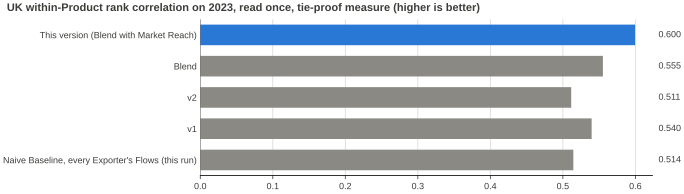

In [5]:
reporting.ranking_by_version(bundle)

**Conclusion.** On 2023, read once, the served version, the Blend with Market Reach, ranks UK Markets more closely to what the UK exported than the Naive Baseline does (0.600 against 0.514 on the tie-proof measure), and more closely than the Blend (0.555), v1 (0.540) and v2 (0.511), which fell below the Naive Baseline. The success bar stated in advance is met. It is an association on one test year, not a promise of what any Market will buy. Sections 2 to 4 describe the data and the model, section 5 why v2 fell short, section 6 how the model was re-chosen, and section 7 the result and what it cost. Sections 8 to 11 cover Scenarios as Illustrative figures, explanations, the limits and governance, and the conclusions.

## 2. The data: Flows, Zero Cells and policy features

Everything the model knows comes from public trade and country data. This section shows what the target is, how absent trade enters training, and where the policy features come from (*Course:* exploratory data analysis and the data-quality audit, at a scale where the data never sit fully in memory: compact Parquet scanned lazily with Polars).

- **Flows**: CEPII's BACI, HS 2012 revision, release V202601 (ADR 0003). Every non-zero Flow between about 226 Exporters and Importers for about 5,200 Products, 2012–2024, about 142 M in all. BACI reconciles each country's export report with its partners' import reports, so a UK Flow is not HMRC's figure. 2024 is provisional: late reporters are still missing.
- **Gravity and size**: distance, contiguity, language and colonial ties from CEPII Gravity; GDP and population from the World Bank, with the IMF and Gravity filling gaps under one written rule that records each value's source. The served version also fills the small Markets still missing them from UN national accounts, Statistics Netherlands and the CIA World Factbook, so they stop falling down the model's missing-value branch.
- **Policy features**: Trade Agreement, Customs Union and EU, CPTPP and EFTA membership per pair and year, from the WTO's RTA database with per-member dates (`docs/research/trade-agreement-coverage.md`), and the Applied Tariff from UNCTAD TRAINS, carried forward from 2021 and zero under an agreement (ADR 0006). These are the only columns a Scenario changes.

Flows per year, with world value and the UK's share of it:

In [6]:
if FIXTURE_MODE:
    flows = build_world().flows.lazy()
else:
    # Downloaded and converted by the BACI build step (`baci.prepare`, in scripts/rebuild.py); read here.
    flows = baci.scan_flows()
flows.head(5).collect()

year,exporter,importer,hs6,value_usd
i16,enum,enum,enum,f64
2012,"""AFG""","""ALB""","""610469""",2734.0
2012,"""AFG""","""ALB""","""630900""",120.0
2012,"""AFG""","""DZA""","""091099""",1185.0
2012,"""AFG""","""ARG""","""392630""",1295.0
2012,"""AFG""","""ARG""","""710310""",98.0


In [7]:
flow_summary = baci.summarise_flows(flows)
flow_summary

year,flows,products,exporters,importers,world_value_usd,uk_value_usd,uk_share
i16,u32,u32,u32,u32,f64,f64,f64
2012,9012155,5199,226,226,1.7973e13,4.3977e11,0.024469
2013,9787220,5199,227,227,1.8226e13,4.4915e11,0.024643
2014,10205742,5199,226,226,1.8463e13,4.7317e11,0.025628
2015,10782381,5199,226,226,1.6230e13,4.1965e11,0.025857
2016,10868820,5199,226,226,1.5814e13,3.9603e11,0.025043
…,…,…,…,…,…,…,…
2020,11150663,5199,226,226,1.7229e13,3.7261e11,0.021627
2021,11673491,5199,226,226,2.1575e13,4.1103e11,0.019051
2022,11677171,5198,226,226,2.4261e13,4.5776e11,0.018868


**Skew.** Flow values are extremely skewed: the mean UK Flow is about a hundred times its median. That is why the model's loss is Tweedie rather than squared error on raw values (*Course:* descriptive statistics: a skewed variable is described by its median, and one huge value can rule a squared loss; section 4).

In [8]:
uk_latest = flows.filter((pl.col("exporter").cast(pl.String) == baci.UK) & (pl.col("value_usd") > 0))
uk_latest.group_by("year").agg(
    mean_usd=pl.col("value_usd").mean(),
    median_usd=pl.col("value_usd").median(),
    markets=pl.col("importer").n_unique(),
    products=pl.col("hs6").n_unique(),
).sort("year").collect()

year,mean_usd,median_usd,markets,products
i16,f64,f64,u32,u32
2012,1.4536e6,24909.0,218,5169
2013,1.3899e6,21228.0,222,5177
2014,1.4260e6,19991.0,222,5166
2015,1.2399e6,17110.0,222,5173
2016,1.1571e6,14837.0,221,5174
…,…,…,…,…
2020,1.0978e6,12682.0,221,5157
2021,1.2207e6,12645.0,222,5158
2022,1.3771e6,12577.0,223,5145


**Zero Cells.** BACI records only non-zero Flows, so an absent pair means zero *or* unreported. A model of Export Potential must also learn where trade does not happen, but the full Exporter × Importer × Product × year grid has about 3.45 bn cells. Training therefore adds **Zero Cells**: the Exporter exports the Product to someone and the Importer imports it from someone, but not from each other. Every UK Zero Cell is kept, because New Market and New Product Opportunities are UK Zero Cells. Other Exporters' are sampled at 5% and weighted by 20, so weighted totals stay unbiased (the Horvitz–Thompson estimator; *Course:* class imbalance, handled by subsampling the majority and reweighting it, so the loss still sees zeros in their true proportion).

Training rows per year, the Zero Cells sampled and the relevant zeros they stand for:

In [9]:
from exportspredictor import features

if FIXTURE_MODE:
    feature_world = build_world()
    feature_table = features.build_features(
        features.training_rows(feature_world.flows, rate=0.5), feature_world.flows, feature_world.sources
    ).lazy()
else:
    feature_dir = features.features_dir()  # written by `python -m exportspredictor.features`; read here, not rebuilt
    feature_table = pl.scan_parquet(feature_dir / "training_*.parquet")

is_zero = pl.col("value_usd") == 0
feature_table.group_by("year").agg(
    rows=pl.len(),
    sampled_zeros=is_zero.sum(),
    relevant_zeros_estimated=pl.col("weight").filter(is_zero).sum(),
).sort("year").collect()

year,rows,sampled_zeros,relevant_zeros_estimated
i16,u32,u32,f64
2012,11558439,3052315,5.1584376e7
2013,12429696,3209063,5.4660132e7
2014,12864385,3284528,5.6076104e7
2015,13551475,3480738,5.9783932e7
2016,13534054,3390731,5.8126653e7
…,…,…,…
2020,13757874,3390789,5.80532e7
2021,14264822,3446737,5.9061523e7
2022,14246975,3449690,5.9009509e7


**Data quality.** Every Exporter and Importer maps to an ISO3 code with Gravity features (the first cell below, real data only). Before trusting BACI as the target, its UK Flows were checked against HMRC's own 2023 Overseas Trade Statistics, an independent primary source (*Course:* the data-quality audit, taken beyond the notes). HMRC records about a fifth more than BACI (19%, printed below), almost all for known reasons: value HMRC does not attribute to a Product or Market, and non-monetary gold. Pairs that both sources record agree closely in rank (0.89), so BACI is a sound target for the *shape* of UK trade, which is what the ranking uses (`docs/research/baci-hs12-feasibility.md`).

In [10]:
from exportspredictor import gravity
from exportspredictor.paths import data_dir

if not FIXTURE_MODE:
    # Built by the gravity step (`python -m exportspredictor.gravity`, in scripts/rebuild.py); read here, not rebuilt.
    derived = data_dir() / "derived"
    in_flows = pl.concat(
        [flows.select(baci_iso3=pl.col(side).cast(pl.String)) for side in ["exporter", "importer"]]
    ).unique().collect()
    # Only countries that appear in the 2012-2024 Flows matter; BACI's file also lists retired codes.
    country_map = pl.read_parquet(derived / "country_map.parquet").join(in_flows, on="baci_iso3", how="semi")
    country_year = pl.read_parquet(derived / "country_year.parquet").filter(pl.col("iso3").is_in(country_map["iso3"].implode()))
    print("Exporters and Importers in the Flows:", country_map["baci_iso3"].n_unique())
    print("... with no Gravity pair features:", gravity.unresolved(country_map).height)
    print("... with no WDI data:", country_map.filter(~pl.col("in_wdi")).height)
    display(country_map.filter((pl.col("baci_iso3") != pl.col("iso3")) | pl.col("gravity_proxy").is_not_null()))

Exporters and Importers in the Flows: 227
... with no Gravity pair features: 0
... with no WDI data: 19


baci_code,name,baci_iso3,iso3,gravity_proxy,in_gravity,in_wdi
i64,str,str,str,str,bool,bool
260,"""Fr. South Antarctic Terr.""","""ATF""","""ATF""","""REU""",true,false
490,"""Other Asia, nes""","""S19""","""TWN""",null,true,false
652,"""Saint BarthÃ©lemy""","""BLM""","""BLM""","""GLP""",true,false


In [11]:
if FIXTURE_MODE:
    print("Fixture mode: the HMRC cross-check needs the real downloads (FIXTURE_MODE = False).")
else:
    from exportspredictor import hmrc

    # The allocated OTS table is written by `hmrc.build` (in scripts/rebuild.py); read here, not rebuilt.
    hmrc_check = hmrc.crosscheck(
        hmrc.load(), hmrc.baci_uk_exports(flows, country_map)
    )
    print(hmrc_check["text"])
    display(pl.DataFrame([{key: value for key, value in hmrc_check.items() if key.endswith("_usd")}]))
    display(pl.DataFrame(hmrc_check["by_sector"]))
    display(pl.DataFrame(hmrc_check["by_market"]))
    print(hmrc_check["pairs"])

HMRC's Overseas Trade Statistics record $528.6bn of UK goods exports in 2023 (at $1.2434 per £), 19% more than BACI's $443.0bn. $30.6bn of HMRC's total is not attributed to a Product or a Market, so BACI cannot hold it at HS6 level.


ots_usd,baci_usd,difference_usd,no_product_usd,no_market_usd,allocated_ots_usd
f64,f64,f64,f64,f64,f64
5.2861e11,4.4295e11,8.5655e10,2.7174e10,3.4067e9,4.9803e11


sector,ots_usd,baci_usd,difference_usd
str,f64,f64,f64
"""71""",8.0818e10,4.4021e10,3.6797e10
"""84""",8.6574e10,7.7297e10,9.2774e9
"""85""",2.8518e10,2.4014e10,4.5040e9
"""29""",1.3579e10,1.0489e10,3.0902e9
"""30""",2.7656e10,2.5081e10,2.5756e9
"""90""",2.1551e10,1.9477e10,2.0739e9
"""28""",1.8405e9,3.5791e9,-1.7386e9
"""22""",1.0813e10,1.2167e10,-1.3544e9
"""89""",1.6053e9,2.7663e9,-1.1610e9


iso3,ots_usd,baci_usd,difference_usd
str,f64,f64,f64
"""CHE""",3.5504e10,7.2625e9,2.8242e10
"""USA""",7.1756e10,6.1056e10,1.0700e10
"""BEL""",2.5238e10,1.7530e10,7.7076e9
"""IRL""",3.4319e10,2.9147e10,5.1724e9
"""IND""",1.2826e10,7.7478e9,5.0785e9
"""NLD""",3.7357e10,3.3201e10,4.1557e9
"""QAT""",4.5298e9,2.3539e9,2.1759e9
"""DEU""",4.0344e10,3.8194e10,2.1493e9
"""ITA""",1.2245e10,1.0140e10,2.1056e9


{'in_both': 219668, 'ots_only': 1739, 'baci_only': 108006, 'spearman': 0.8895008884616539, 'close_share': 0.25, 'close_value_share': 0.5513996983730932}


**Policy features.** A membership counts in a year if it began before 1 July, Gravity's rule: EU–Japan counts from 2019, UK–Australia and UK–New Zealand from 2023, and the UK's CPTPP accession (December 2024) only from 2025. Checked against CEPII Gravity for 2012–2021, the two sources agree on every agreement the Scenarios and Event Backtests rely on, and where they differ the reasons are known, mostly gaps in Gravity (*Course:* feature engineering with data lineage: every flag traces to a dated primary record). The UK's Trade Agreements for a few Markets, then the cross-check:

In [12]:
if FIXTURE_MODE:
    print("Fixture mode: the fixture world carries its own trade_agreement column (section 4).")
else:
    policy_files = policy.policy_paths()  # written by `python -m exportspredictor.policy`; read here, not rebuilt
    agreements = pl.read_parquet(policy_files["agreements"])
    trading_blocs = pl.read_parquet(policy_files["trading_blocs"])
    print(agreements.height, "pair-years with a Trade Agreement;", trading_blocs.height, "country-years in a tracked Trading Bloc")

113028 pair-years with a Trade Agreement; 459 country-years in a tracked Trading Bloc


In [13]:
if not FIXTURE_MODE:
    uk_rows = pl.DataFrame(
        {"exporter": "GBR", "importer": ["FRA", "JPN", "AUS", "NZL", "MEX", "USA"]}
    ).join(pl.DataFrame({"year": list(range(2018, 2025))}, schema={"year": pl.Int32}), how="cross")
    uk_policy = policy.attach_policy(uk_rows, agreements, trading_blocs)
    display(uk_policy.pivot(on="year", index="importer", values="trade_agreement"))
    display(uk_policy.pivot(on="year", index="importer", values="customs_union"))
    display(uk_policy.filter(pl.col("importer") == "FRA").select("year", "eu_o", "cptpp_o", "efta_o"))

importer,2018,2019,2020,2021,2022,2023,2024
str,i8,i8,i8,i8,i8,i8,i8
"""FRA""",1,1,1,1,1,1,1
"""JPN""",0,1,1,1,1,1,1
"""AUS""",0,0,0,0,0,1,1
"""NZL""",0,0,0,0,0,1,1
"""MEX""",1,1,1,1,1,1,1
"""USA""",0,0,0,0,0,0,0


importer,2018,2019,2020,2021,2022,2023,2024
str,i8,i8,i8,i8,i8,i8,i8
"""FRA""",1,1,1,0,0,0,0
"""JPN""",0,0,0,0,0,0,0
"""AUS""",0,0,0,0,0,0,0
"""NZL""",0,0,0,0,0,0,0
"""MEX""",0,0,0,0,0,0,0
"""USA""",0,0,0,0,0,0,0


year,eu_o,cptpp_o,efta_o
i32,i8,i8,i8
2018,1,0,0
2019,1,0,0
2020,0,0,0
2021,0,0,0
2022,0,0,0
2023,0,0,0
2024,0,0,0


In [14]:
if not FIXTURE_MODE:
    gravity_policy = policy.read_gravity_policy()  # from the gravity step's extract (section 2)
    crosscheck, disagreements = policy.gravity_crosscheck(agreements, trading_blocs, gravity_policy)
    display(crosscheck)

feature,pair_years,agreement_rate,both,ours_only,gravity_only,positive_overlap
str,u32,f64,u32,u32,u32,f64
"""trade_agreement""",549900,0.955286,58938,21426,3162,0.705625
"""eu""",2350,0.999574,276,0,1,0.99639


**Conclusion.** BACI gives a consistent HS 2012 panel of about 142 M Flows, small enough to scan lazily on one machine, and close to HMRC on the shape of UK trade. Three of its properties shape later choices: values are extremely skewed (a Tweedie loss), absent Flows mean zero or unreported (sampled, reweighted Zero Cells, and weaker rankings where reporting is poor), and 2024 is provisional (a 2023 test year). The policy features come from dated primary records, and they bound what any Scenario Effect can mean.

## 3. Features and the leakage rules

Every model input is computed once, in `exportspredictor.features`, which training and the API both import, so a feature cannot drift between them (*Course:* training/serving skew, removed by construction). This section lists the features, then states the three rules that keep the evaluation honest, each with its reason.

| Group | Features | What it captures |
|---|---|---|
| Gravity | log GDP and population of both countries, log distance, contiguity, common language, colonial tie, common colonizer | size and closeness of the two countries |
| Supply | `log_supply_loo`, `rca_loo`: the Exporter's exports of the Product to *other* Importers, and its revealed comparative advantage | what the Exporter makes and sells well |
| Demand | `log_demand_loo`, `high_income_share_loo`: the Importer's imports of the Product from *other* Exporters, and the share from high-income ones | what the Market buys, and from whom |
| Product | `sector` (HS2 chapter), `relatedness` (closeness to what the Exporter already exports competitively) | Sector differences and nearby capabilities |
| Re-export | `reexport_ratio`: the Importer's exports of the Product against its imports | Re-export Hubs (ADR 0005) |
| Policy | Trade Agreement, Customs Union, EU, CPTPP and EFTA flags; `log_applied_tariff` | the only columns a Scenario changes (ADR 0006) |

### The leakage rules

1. **Out-of-fold scoring** (ADR 0001). UK Product–Market pairs are split into five folds by a hash of the pair, so all of a pair's years share a fold, and each UK Export Potential comes from the fold model that never saw that pair. *Why*: a model that had seen the pair would copy its Actual Exports back and shrink its Export Gap towards zero (*Course:* out-of-fold target encoding, applied to the whole model rather than to one feature).
2. **Leave-one-out supply features.** Every aggregate a row feeds leaves out the row's own Flow, so UK supply of a Product excludes the target Market. *Why*: otherwise the feature contains the answer (*Course:* target leakage: use only what exists without the target). The pair's trade in other Products is left out too, because it would absorb the policy effect. One gap is accepted and recorded in ADR 0001: a non-UK row's demand still includes the UK's Flow to that Market.
3. **The time split.** Fit on 2012–2021, choose on 2022, test once on 2023; clip ranges, the Sector encoder and every aggregate are fitted on training years only. *Why*: a choice or a preprocessing step that saw the test year makes its score optimistic, silently (*Course:* preprocessing and evaluation leakage; train, validation and test splits, split by time when predicting later years).

Tests enforce each rule (`tests/test_features.py`, `tests/test_folds.py`): changing a held-out pair's Flow moves none of its own features, and distorting one fold's UK labels a thousandfold leaves that fold's scores unchanged. One UK row's features, whisky (`220830`) to Japan:

In [15]:
feature_table.filter(
    (pl.col("exporter") == "GBR") & (pl.col("importer") == "JPN") & (pl.col("hs6").cast(pl.String) == "220830")
).sort("year").tail(1).collect().transpose(include_header=True, column_names=["value"])

column,value
str,str
"""exporter""","""GBR"""
"""importer""","""JPN"""
"""hs6""","""220830"""
"""year""","""2024"""
"""log_gdp_o""","""28.938148"""
…,…
"""log_applied_tariff""","""0.0"""
"""tariff_imputed""","""true"""
"""mfn_tariff""","""0.0"""


**Conclusion.** One function builds every input for training and serving alike. Three tested rules mean that no UK Export Potential is computed by a model that saw its pair, from a feature that contains its own Flow, or under a choice that saw the test year. The one accepted leak, the UK inside other rows' demand, is small and recorded in ADR 0001.

## 4. The model and how it is scored out-of-fold

The model is one gradient-boosted tree ensemble per fold, trained with XGBoost on the GPU, and the served Export Potential is a **Blend** of it with the Naive Baseline (section 6 says how that form was chosen). This section says what each part does and how a UK pair is scored.

- **Gradient boosting** (*Course:* ensembles: boosting adds small trees that each correct the errors of the last). Depth-12 trees and a learning rate of 0.1, v2's configuration.
- **Tweedie loss** (*Course:* loss functions; choosing a loss for a skewed target). Flows are non-negative, often zero and very skewed. The Tweedie objective models a log mean whose variance grows with the mean, so a few huge Flows do not rule the fit.
- **Monotone constraints** on the policy features: +1 on every membership and −1 on the Applied Tariff, which is clipped to its training range (ADR 0006). Adding a Trade Agreement never lowers Export Potential; ADR 0008 kept the constraints after testing them against the ranking (section 6).
- **Five fold models** (*Course:* k-fold cross-validation, used here for cross-fitting rather than only for a score). Fold model *k* trains on every non-UK row plus the UK pairs outside fold *k*, and scores only fold *k*.
- **Memory** (*Course:* GPUs and device placement). The 162 M training rows of 2012–2023 do not fit the RTX 3080's 10 GB, so they stream year by year into a `QuantileDMatrix`, and the largest hash sample of non-UK rows that fits is kept and reweighted (ADR 0004). Every UK row is kept.

The served configuration, read from the artefact:

In [16]:
{key: bundle.metadata.get(key) for key in ("model_form", "params", "rounds", "n_folds", "non_uk_sampling_rate", "training_seconds")}

{'model_form': {'form': 'blend',
  'naive_weight': 0.3,
  'market_reach': {'form': 'share',
   'beta': 4.0,
   'pseudo_count': 5.0,
   'lag_years': 1,
   'reference_year': 2023,
   'constant': 0.05659889926731445}},
 'params': {'max_depth': 12,
  'min_child_weight': 3.0468601316016213,
  'subsample': 0.9158324106709628,
  'colsample_bytree': 0.8794644314402613,
  'reg_lambda': 4.953922320798769,
  'tweedie_variance_power': 1.2655329893555092,
  'eta': 0.1},
 'rounds': 1279,
 'n_folds': 5,
 'non_uk_sampling_rate': 0.5894,
 'training_seconds': 3940.55}

### From Export Potential to the Export Gap

The fold models, refit on 2012–2023, score the UK grid of each **Gap Period** year, 2022 to 2024, each pair by the fold model that held it out. The **Export Gap** is the mean of the three yearly gaps (Export Potential minus Actual Exports, a year with no Flow counting as $0). Averaging damps the year-to-year noise of single shipments (*Course:* bagging averages to cut variance). 2020 and 2021 are left out because COVID and the end of the Brexit transition describe shocks, not fundamentals. The Baseline table holds the gaps, and the 2024 Export Potential that Scenarios start from:

In [17]:
baseline = bundle.baseline.join(bundle.products, on="hs6", how="left").join(
    bundle.markets.rename({"name": "market"}), on="iso3", how="left"
)
baseline.select(
    pairs=pl.len(),
    products=pl.col("hs6").n_unique(),
    markets=pl.col("iso3").n_unique(),
    pairs_with_exports=(pl.col("actual_exports_usd") > 0).sum(),
    actual_exports_usd=pl.col("actual_exports_usd").sum(),
    export_potential_usd=pl.col("export_potential_usd").sum(),
    baseline_export_potential_usd=pl.col("baseline_export_potential_usd").sum(),
    opportunities=(pl.col("export_gap_usd") > 0).sum(),
)

pairs,products,markets,pairs_with_exports,actual_exports_usd,export_potential_usd,baseline_export_potential_usd,opportunities
u32,u32,u32,u32,f64,f64,f64,u32
1156050,5138,225,416566,3.4618e11,2.7719e11,3.0005e11,898686


How one pair's Export Gap is formed, year by year: whisky (`220830`) to Japan.

In [18]:
whisky_japan = (pl.col("hs6") == "220830") & (pl.col("iso3") == "JPN")
display(bundle.history.filter(whisky_japan, pl.col("export_gap_usd").is_not_null()))
bundle.baseline.filter(whisky_japan).select(
    "export_potential_usd", "actual_exports_usd", "export_gap_usd", "baseline_export_potential_usd"
)

hs6,iso3,year,actual_exports_usd,export_potential_usd,export_gap_usd,tariff_imputed
str,str,i16,f64,f64,f64,bool
"""220830""","""JPN""",2022,3.06884166e8,5.5561e7,-2.5132e8,true
"""220830""","""JPN""",2023,3.14956262e8,6.4738e7,-2.5022e8,true
"""220830""","""JPN""",2024,3.3388241e8,6.2171e7,-2.7171e8,true


export_potential_usd,actual_exports_usd,export_gap_usd,baseline_export_potential_usd
f64,f64,f64,f64
6.0823e7,3.1857e8,-2.5775e8,6.2171e7


**Conclusion.** Every UK Export Potential comes from a fold model that held its pair out, under a loss suited to skewed, zero-heavy Flows and constraints that fix the direction of every policy feature. Every Export Gap averages three recent years. Sections 5 and 6 turn to what the model does well and what the Blend adds.

## 5. What v2 showed

v2, the version before this one, was the model alone, chosen step by step on Tweedie deviance. On 2023 it ranked UK Markets below the Naive Baseline. This section shows two reasons: the measure it was chosen on moved against the ranking, and it was weak on whether the UK exports at all.

### Every choice was made on deviance

Early stopping, the feature ablation, the learning curve and the hyperparameter search (Bayesian, TPE with a median pruner) all chose on the 2022 Tweedie deviance, with the UK ranking only as a guardrail (ADR 0002). The guardrail passed by a hair, −0.0099 against a limit of −0.01. Among the three configurations the search confirmed on every Product, the winner had the lowest deviance and the lowest UK ranking (*Course:* loss functions vs evaluation metrics: training optimises the loss it is given, and the metric people read can disagree with it). The search's confirmed configurations, from the artefact (details in the appendix):

In [19]:
pl.DataFrame(bundle.metadata["search"]["confirmation"]).select("trial", "rounds", "validation_deviance", "uk_spearman")

trial,rounds,validation_deviance,uk_spearman
i64,i64,f64,f64
15,1198,364.253023,0.528035
23,1688,365.581411,0.530984
19,1829,365.841244,0.535824


### Weaker on whether the UK exports at all

Most UK pairs are Zero Cells, so a Product's order of Markets is decided largely by which Markets have any UK trade. On the 2022 validation fold, v2's configuration ranks Markets the UK already serves better than the Naive Baseline does (`non_zero_spearman`), but it ranks "any Flow against none" worse (`zero_vs_non_zero_spearman`). The Naive Baseline knows something about where trade happens that the model lacks. From the experiment loop's record:

In [20]:
record = bundle.metadata["ranking_experiments"]
measures = ["selection_measure", "non_zero_spearman", "zero_vs_non_zero_spearman", "tweedie_deviance"]
pl.DataFrame([
    {"model": f"v2's configuration ({record['noise_floor']['arms'][0]['arm']})", **{m: record["noise_floor"]["arms"][0].get(m) for m in measures}},
    {"model": "Naive Baseline", **{m: record["naive"].get(m) for m in measures}},
])

model,selection_measure,non_zero_spearman,zero_vs_non_zero_spearman,tweedie_deviance
str,f64,f64,f64,f64
"""v2's configuration (seed 0)""",0.533391,0.525292,0.485796,371.6189
"""Naive Baseline""",0.547213,0.449941,0.509227,4331.893122


On 2023, under a comparison with v1 fixed before the test year was read, v2 estimated the size of Flows better than v1 but ranked UK Markets less well. The gain ladder associates most of that drop with v2's new training rows rather than its features or tuning. Both are frozen in the appendix.

**Conclusion.** v2 was a good model of the size of trade: its deviance over all Exporters was the lowest of any version. It was chosen on that, and the ranking an Advisor reads fell below the Naive Baseline. Two lessons carry into section 6: choose on the measure that is reported, and use what the Naive Baseline knows about whether trade happens at all.

## 6. Re-choosing the model on the Selection Measure

The model was re-chosen by an experiment loop (`exportspredictor.loop`, ADR 0008) under a rule fixed in code before any experiment was read. This section explains the rule, then shows every Arm the loop ran, failures included, the five-fold confirmation and the Blend it chose. Everything here is on the 2022 validation year; the loop's data refuse 2023 (`experiments.TestYearRead`). Full detail: `docs/research/opportunity-ranking-experiments.md`.

### The rule

- **Selection Measure**: section 1's headline measure, moved to the validation year: the within-Product rank correlation for held-out UK pairs in 2022, averaged over Products. Every other metric, Tweedie deviance included, is reported and never chosen on. Rounds are early-stopped on it too.
- **Noise Floor**: v2's configuration trained with three seeds, which change both the row sample and XGBoost's seed. The spread of the Selection Measure across seeds is how far it moves by chance (*Course:* seeds, run-to-run noise and the noise band: a gap smaller than the spread between runs is noise, not evidence).
- **Win Threshold**: twice the Noise Floor's standard deviation, and at least 0.005. An Arm is kept only if it beats the best so far by more than this; otherwise every Arm of that experiment is dropped (*Course:* defensible selection and the one-standard-error rule, made stricter and fixed in advance).
- Arms run on one seed against a cached base, so comparisons are paired. No Arm was added or re-run after its result was seen.

In [21]:
summary = model_choice.ranking_summary(bundle.metadata.get("ranking_experiments"))
print(model_choice.how_chosen(bundle.metadata, report)["text"])
None if summary is None else {key: summary[key] for key in ("validation_year", "noise_floor_sd", "win_threshold")}

Every choice was made on one Selection Measure, on 2022 only: Mean over Products of the Spearman correlation between Export Potential and Actual Exports across Markets, on the held-out fold's UK pairs in the validation year, every non-Excluded Product. An Arm was kept only if it beat the best so far by more than the Win Threshold, 0.0089 (twice the Noise Floor's standard deviation, three seeds of one configuration). Of 8 experiments, decided in 10 steps, 1 kept a change (1–2. Naive Baseline: blend).


{'validation_year': 2022,
 'noise_floor_sd': 0.004435207007510482,
 'win_threshold': 0.008870414015020964}

### Ties cannot win

The open review of 2022 found that the Selection Measure could be won by saying less. It gave tied values their average rank, and most UK Actual Exports are tied zeros. Flooring the Blend's Export Potential at $1,000 tied 52% of pairs with those zeros and lifted the 2022 measure from 0.5635 to 0.6062, as much as the Blend's whole win over the model alone, while ranking nothing better. Early trees, full of exact ties, could win early stopping the same way.

Ties in Export Potential are now broken in a fixed pseudo-random order, a stable hash of Product and Market (`exportspredictor.selection_measure`). A tied block then ranks, on average, no better than a random order, so tying can only lose: the same $1,000 floor lowers the measure to 0.5431, while the Blend itself is unchanged to four places. The loop's past decisions were made on the old measure and are re-checked under the fixed one (ADR 0008, amended). 2023 is not re-read for this (*Course:* baselines and metrics. Accuracy rewards a do-nothing model on imbalanced data, and in the same way a measure that rewards a flatter ranking must be fixed before anything is chosen on it).

### Every Arm

Seven experiments, in order: blend with the Naive Baseline or start from it; select configurations on ranking (v1's, three from v2's search, shallower trees); a two-part model (whether trade happens, then how much); two Zero Cell scopes; three Product-detail features; the monotone constraints off; and, on rebuilt feature files, the Exporter count. The table lists every Arm with its Selection Measure, its change on the best so far, its best round and whether it was kept; the chart draws each change against the Win Threshold. The first cell also checks that the artefact records the loop's saved results.

In [22]:
ranking_results = bundle.metadata["ranking_experiments"] if FIXTURE_MODE else loop.ranking_record(loop.load())
print("The artefact records the experiment loop's saved results:", ranking_results == bundle.metadata["ranking_experiments"])
with pl.Config(tbl_rows=20):
    display(reporting.experiments(bundle))

The artefact records the experiment loop's saved results: True


experiment,arm,selection_measure,change,rounds,kept,stopped_early
str,str,f64,f64,i64,bool,bool
"""1–2. Naive Baseline""","""blend""",0.577148,0.043757,951,true,false
"""1–2. Naive Baseline""","""starting point""",0.562088,0.028697,13,false,true
"""3. select on ranking""","""v1""",0.554325,-0.022823,1,false,true
"""3. select on ranking""","""search trial 15""",0.577148,-1.1102e-16,951,false,false
"""3. select on ranking""","""search trial 23""",0.579297,0.002149,1697,false,false
"""3. select on ranking""","""search trial 19""",0.576441,-0.000707,1858,false,false
"""3. select on ranking""","""depth 6""",0.564495,-0.012653,12,false,true
"""4. two-part model""","""two-part""",0.562748,-0.0144,400,false,false
"""5. scope: UK Zero Cells""","""UK Zero Cells sampled""",0.576309,-0.000839,756,false,false


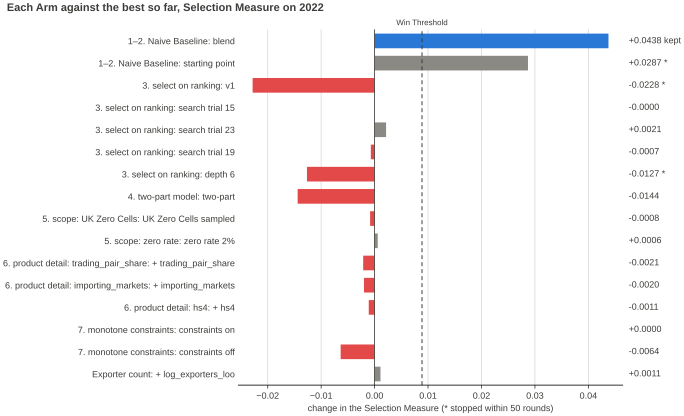

In [23]:
reporting.experiments_chart(bundle)

**The stopping-rule caveat.** Four Arms reached their best round within their first 50 and then stopped: v1's configuration, depth 6, the starting point and the two-part model's binary part (the table shows its size part's rounds). Rounds stop on the model alone, while Arms are chosen on the Blend, so for these four the result reflects the stopping rule as much as the idea; with more patience, or stopping on the Blend, they might have scored higher. The rule was kept, because changing it after seeing results would have meant adding Arms mid-run. A dropped Arm here is not a disproved idea. The one fully trained alternative configuration (search trial 23) still landed inside the noise.

**What the Arms say.** Only the Blend cleared the Win Threshold. Every later Arm landed within about +0.003 of the Blend or below it: the configuration barely matters once blended, the Zero Cell scopes and Product-detail features moved nothing beyond the noise, and removing the monotone constraints ranked slightly worse, so they stay (ADR 0008).

### The five-fold confirmation

A one-fold win could be the luck of the fold. So the Blend and v2 (the same fold model, alone) were trained on all five folds and measured on 2022, each fold model scoring only the UK pairs it held out (*Course:* k-fold cross-validation: a score and its spread across folds). Fold by fold, then over every UK pair of 2022 (`all`):

In [24]:
reporting.confirmation(bundle)

fold,winner,v2,difference,win_threshold
str,f64,f64,f64,f64
"""0""",0.577148,0.533391,0.043757,0.00887
"""1""",0.574481,0.52949,0.044992,0.00887
"""2""",0.575359,0.533813,0.041546,0.00887
"""3""",0.57387,0.528671,0.045198,0.00887
"""4""",0.574761,0.534845,0.039915,0.00887
"""all""",0.563464,0.520579,0.042885,0.00887


The Blend beats v2 on every fold, each time by several times the Win Threshold, and over every pair it also beats the Naive Baseline, which v2 alone does not.

### The Blend

$$\text{Export Potential} = \exp\big(0.7\,\log \text{model} + 0.3\,\log \text{Naive Baseline}\big),$$

each side floored at $1, with the Naive Baseline's weight, 0.3, chosen on the Selection Measure. The Naive Baseline orders Markets by whether trade is plausible at all, which is where v2 was weak; the model estimates size among the Markets the UK serves, from gravity, demand, Relatedness and policy. A weighted geometric mean keeps Export Potential in dollars, so the Export Gap is still defined. The Naive Baseline has no policy features, so a Scenario moves only the model's share: every Scenario Effect is the model's, scaled by 0.7 on the log scale (*Course:* ensembles, here two members with a fixed weight chosen as a hyperparameter on validation data).

The Blend is then scaled by **Market Reach** (ADR 0010): Export Potential × exp(4 · offset) × c, where a Market's offset is the log of the UK's share of the Products it imports against its share across all Markets, and c keeps the UK's total unchanged. It is the course's out-of-fold target encoding applied to the Market: each pair takes the encoding learned from other folds' pairs in the year before, never from its own Flows (*Course:* out-of-fold target encoding). On 2022 it lifted the Selection Measure from 0.5635 to 0.6041. An Export Gap now compares a Product with the UK's other Products in its Market; the app states each Market's reach beside it.

In [25]:
print(bundle.model_form.text)

Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale, then scales it by each Market's Market Reach (β = 4), learned from the UK's other Products there in 2023.


**The Exporter count and the gravity fill** (`docs/research/exporter-count-2022.md`). The 2022 error review's strongest candidate feature was the **Exporter count**: how many other Exporters sell the Product into the Market. It was tried as an Arm on feature files rebuilt with it, against a base retrained on the same files, both with Market Reach. It added +0.0011 against a Win Threshold of 0.0089, so it was dropped: the demand features and Market Reach already carry what it knows. The same rebuild filled GDP and population for small Markets from documented sources. That moved the measure by −0.0001, inside the noise; it is kept as a data correction, not an Arm (*Course:* data cleaning: fill from a documented source rather than impute blindly).

**Conclusion.** Under a rule fixed before any result was read, the loop kept one change, the Blend with the Naive Baseline, which beat v2 on all five folds of 2022 by about five times the Win Threshold, and Market Reach was kept on top of it by the same rule. Everything else, the Exporter count and four Arms the stopping rule cut short included, stayed inside the noise or below it, and is reported rather than hidden.

## 7. The 2023 result and what it cost

The final run trained the served version's fold models, the Blend with Market Reach on the rebuilt feature files, and read 2023 once, after every choice was fixed on 2022 (*Course:* train, validation and test splits: look at the test set once). This section reads that result beside the Blend, v2, v1 and the Naive Baseline, then what Market Reach changed, what choosing on the ranking cost, and the round count.

The test-year fold models train on 2012–2022 and score 2023, each UK pair by the fold model that held it out, as the Baseline is scored. 2023 shaped no choice: the search, the loop and the confirmation never read it, and a test multiplies every 2023 Flow by 1,000 and checks that the search results do not move.

### The result, read once

Every version's UK ranking on the old measure and the tie-proof one, and its costs, from the evaluation report. The earlier versions' tie-proof figures come from re-scoring their saved 2023 scores; ties were rare in their continuous scores, so both measures agree to three places. Two Naive Baseline rows are shown because their Flows differ slightly (every Exporter's, as the Blend uses, or v2's training rows); they agree closely, so the verdict does not depend on which.

In [26]:
versions = report["earlier_versions"]
pl.from_dicts(versions["rows"] + versions["naive"], infer_schema_length=None)

name,uk_ranking,uk_ranking_tie_proof,lift,size_matched_lift,tweedie_deviance_all_exporters,tweedie_deviance_uk,version
str,f64,f64,f64,f64,f64,f64,str
"""This version (Blend with Marke…",0.59959,0.59959,4.291402,0.752147,468.48252,2537.431944,null
"""Blend""",0.555192,0.555192,4.993143,0.760532,433.764599,566.346004,"""20261118T185910Z"""
"""v2""",0.511496,0.511496,5.226938,0.787659,355.528809,568.588334,"""20261118T100524Z"""
"""v1""",0.53969,0.53969,5.798361,0.833181,null,null,null
"""Naive Baseline, every Exporter…",0.523115,0.514445,null,null,null,null,null
"""Naive Baseline as reported for…",0.523325,null,null,null,null,null,null


On the Markets that import the most, where Advisors usually look, the same tie-proof measure for each version (the earlier versions from their saved scores), then what Market Reach, the change this version keeps, did to the ranking, Lift and the Potential Range:

In [27]:
reporting.large_markets_by_version(bundle)

version,30 largest Markets,60 largest Markets
str,f64,f64
"""This version (Blend with Marke…",0.570064,0.604461
"""Blend""",0.51157,0.537386
"""v2""",0.537994,0.556363
"""v1""",0.509323,0.541787
"""Naive Baseline, every Exporter…",0.355354,0.395754


In [28]:
print(reporting.market_reach_effect(bundle))

Market Reach is the change this version keeps (ADR 0010). On 2023, the UK ranking is 0.600 with it against 0.554 without on the tie-proof Selection Measure (0.600 with it against 0.554 without on the old measure); on the 30 largest Markets 0.570 with it against 0.514 without; on the 60 largest Markets 0.604 with it against 0.543 without. Lift is 4.29 with it against 5.04 without (size-matched 0.75 against 0.77), each held-out Exporter scaled by its own Market Reach. The Potential Range holds 74% with it against 81% without of UK pairs' Gap Period Actual Exports. Market Reach leaves Scenario Effects unchanged: it scales a pair's Export Potential with and without a Scenario alike, so the Event Backtests and the PPML benchmark compare the model's Scenario Effects without it (ADR 0010). These are associations on one test year, not a forecast.


### Every read of 2023

2023 is read once per frozen version (ADR 0009): every choice is made on 2022 and fixed before 2023 is opened, and no 2023 result feeds back into that version. v1, v2 and the Blend each read it once, and this version once. The same run re-scored the earlier versions' saved scores under the tie-proof measure, a second row of kind `re-score`: nothing was trained or chosen, and each version's old-measure figure matched the one it reported. The Test-year Ledger records every read with its Configuration Fingerprint, and the pipeline refuses a second read of a fingerprint unless the override is passed, which is logged too (*Course:* data leakage: repeatedly peeking at test scores). The table below reads only the ledger file.

In [29]:
reporting.test_year_ledger()

date,version,fingerprint,read,command,override,kind,status
str,str,str,str,str,bool,str,str
"""2026-11-17""","""v1 (20261117T010658Z)""","""a77726cf17b0""","""test-year evaluation; the same…","""python -m exportspredictor.eva…",false,"""evaluation""","""completed"""
"""2026-11-18""","""v2 (20261118T042154Z)""","""f7cdd149f731""","""test-year evaluation; a throwa…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-18""","""the Blend (20261118T185910Z)""","""f4d0be3058fd""","""test-year evaluation; Lift and…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-20""","""20261120T221726Z""","""a748777eac4b""","""test-year evaluation; Lift and…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-20""","""20261120T221726Z""","""5153ffef0c6a""","""re-scoring the saved test-year…","""python -m exportspredictor.pip…",false,"""re-score""","""completed"""


Every metric, model against Naive Baseline, for UK pairs scored out-of-fold and for every Exporter's 2023 rows (*Course:* regression metrics, reported beside the ranking measure rather than chosen on):

In [30]:
pl.DataFrame([{"scope": scope, **result["overall"]} for scope, result in report["accuracy"].items()]).drop("group", strict=False)

scope,rows,non_zero_flows,products,actual_usd,model_tweedie_deviance,naive_tweedie_deviance,model_rmse_log,naive_rmse_log,ranked_products,model_spearman_within_product,naive_spearman_within_product
str,i64,i64,i64,f64,f64,f64,f64,f64,i64,f64,f64
"""all_exporters""",14316140,10851880,5138,1.8688e13,468.48252,3954.686672,2.717819,3.328163,5135,0.746859,0.567729
"""uk_out_of_fold""",1156050,325676,5138,3.5331e11,2537.431944,2094.906123,3.097594,2.729484,5138,0.59959,0.514445


### What choosing on the ranking cost

ADR 0008 expected the size of Export Potential to get worse, and it did. The cost, printed from the report:

In [31]:
traded = model_choice.traded_away(report.get("earlier_versions"))
print("No earlier version of this artefact records a lower Tweedie deviance." if traded is None else traded["text"])

Choosing on the ranking traded away accuracy on size: Tweedie deviance over all Exporters is 468.5 for this version against 433.8 for Blend (lower is better), so the size of Export Potential is estimated less well. Size-matched Lift is 0.75 (Blend 0.76). Treat dollar values with more caution than rankings.


**Lift.** Lift asks whether large Export Gaps point at growth. The past is replayed on Exporters held out like the UK: gaps over 2015–2017, then whether each pair's 2023 Flow rose by at least 50% and $100,000. Raw Lift, the top tenth's growth rate over all pairs', is well above 1, but large gaps sit on large pairs, so the **size-matched Lift** compares the top tenth with pairs of similar Export Potential. It is below 1, as it was for v2 and v1: an Opportunity marks a Market worth a look, not one likelier to grow than its peers of the same size. Lift is a tendency, not a forecast (*Course:* lift as a gate number, here with a cluster bootstrap over Exporters and a size-matched control).

In [32]:
lift = report.get("lift")
print(f"Lift: {NOT_RUN}." if lift is None else lift["text"])
None if lift is None else pl.DataFrame(lift["by_decile"]).rename({"decile": "Export Gap tenth (1 = largest)", "rate": "share that grew", "pairs": "weighted pairs"})

For countries the model never trained on, the tenth of Product–Market pairs with the largest Export Gaps averaged over 2015–2017 rose by at least 50% and $100,000 from their 2015–2017 mean by 2023 4.3 times as often as pairs picked at random (95% confidence interval 3.1 to 6.9): 5% of them against 1%. They grew less often than pairs of similar Export Potential (ratio 0.75, 95% interval 0.69 to 0.81). Much of the Lift comes from size: large gaps sit on large pairs, which grow by $100,000 more easily. This is a tendency across many pairs, not a promise that any one Opportunity will grow.


Export Gap tenth (1 = largest),share that grew,weighted pairs
i64,f64,f64
1,0.050055,859421.0
2,0.003987,859440.0
3,0.001378,859412.0
4,0.000721,859436.0
5,0.000489,859420.0
6,0.000442,859440.0
7,0.000396,859420.0
8,0.000023,859420.0
9,0.000023,859440.0


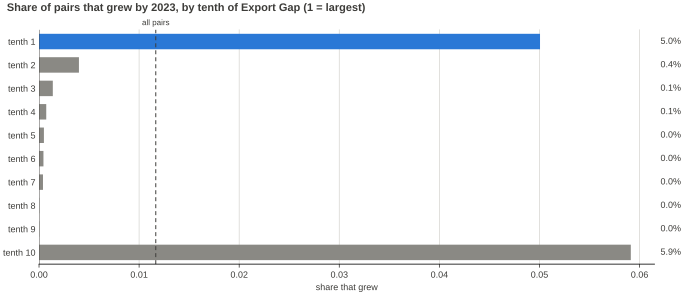

In [33]:
reporting.lift_by_tenth(bundle)

### The round count

The rule says deviance chooses nothing. The Blend's served models broke it in one place: they trained for v2's round count, which the search had early-stopped on Tweedie deviance, and the review found this only after 2023 was read. This version closes it: its rounds come from the Selection Measure, the median of the five-fold confirmation's rounds (1,097), scaled to the fold models' rows (1,279). From the artefact:

In [34]:
reporting.round_count(bundle)

model,chosen_on,rounds_chosen,rounds_trained
str,str,i64,i64
"""served""","""Selection Measure""",1097,1279
"""next rebuild""","""Selection Measure""",1097,null


**Conclusion.** Frozen on 2022, the served version beats the Naive Baseline on 2023 by 0.086 and the Blend by 0.045 on the tie-proof measure, and leads on the 30 and 60 largest Markets too; Market Reach carries nearly all of the gain over the Blend. The cost is size: deviance over all Exporters rose again (468 against the Blend's 434), and the size-matched Lift stays below 1. So the ranking is the part to trust, and dollar values deserve more caution. These are associations on one test year, read once.

## 8. Scenarios and Blocked Opportunities as Illustrative figures

A **Scenario** asks the served model a what-if question: copy the 2024 Baseline rows of the affected Markets, change **only the policy columns** (Trade Agreement, Customs Union, the Trading Bloc flags and the Applied Tariff that goes with them, ADR 0006), and re-predict each pair through `prediction.export_potential` with the fold model that scored its Baseline (ADR 0001). The **Scenario Effect** is the difference. The Naive Baseline has no policy features, so a Scenario moves only the model's share of the Blend, and `exportspredictor.scenarios` checks on every run that no other column moved.

This section shows the Trading Bloc presets and the Blocked Opportunities, then sets them beside a PPML gravity regression and the Event Backtests. That comparison is why every Scenario Effect and Blocked Opportunity value is labelled **Illustrative**: an upper-end association, never a forecast, and never chosen on (ADR 0008). The Scenario note the API serves comes first (*Course:* the counterfactual test, flip one attribute and hold the rest, used as a measurement; and correlation is not causation).

In [35]:
from exportspredictor import illustrative, scenarios

note = illustrative.scenario_note(bundle)
print(f"{note['label']}. {note['text']}")
for part in ("benchmark", "model_association", "event_backtest"):
    print("-", note[part]["text"])
if note["blend"] is not None:
    print("-", note["blend"]["text"])

Illustrative. Scenario Effects and Blocked Opportunity values are illustrative: upper-end associations the model has learned from past trade, shown beside their benchmarks. They are not forecasts, and the model was not chosen on them.
- A PPML gravity benchmark (Sector level, 2012–2024) associates a Trade Agreement with +5.1% in Flows (95% interval -0.4% to +11.0%); published estimates range from +21.0% to +100.0%.
- On the served Model Form (Blend with Market Reach), the model associates adding a Trade Agreement with +34.8% in Export Potential over the 678,216 UK pairs without one (weighted by Baseline Export Potential).
- In the primary Event Backtest (The EU–Japan Economic Partnership Agreement), the model alone associated the agreement with +33% for EU exports to Japan; the observed change against Control Markets was +2% (95% interval -7% to +14%). It covers one agreement's Markets and the model alone, while the model's association above covers every UK pair without a Trade Agreeme

### The Trading Bloc presets

Four presets change only the rows of a bloc's member Markets in the Baseline year. **EU re-join** sets the Trade Agreement, Customs Union and EU flags; **EU Customs Union only** sets the Customs Union; **CPTPP** sets the Trade Agreement and CPTPP flags, with accession treated as complete; **Leave** switches off the UK's membership of every bloc it is in. Joining sets a known Applied Tariff to 0 and leaves a missing one missing; removing an agreement restores the 2021 MFN rate (ADR 0006).

A membership counts in a year only if it began before 1 July, so the 2024 Baseline has no UK CPTPP membership, and the CPTPP preset is a live prediction that 2025 data can check. In 2024 the UK is in no tracked Trading Bloc, so Leave changes nothing. Each preset's Scenario Effect, with its Blocked Opportunities:

In [36]:
preset_results = {
    name: scenarios.run(bundle.baseline_features, bundle.baseline, bundle.fold_models, scenarios.Scenario(preset=name), form=bundle.model_form)
    for name in scenarios.PRESETS
}
pl.DataFrame(
    [
        {
            "preset": scenarios.PRESETS[name].title,
            "pairs_changed": result.pairs.height,
            **result.total(),
            "blocked_opportunities": result.blocked_opportunities(bundle.history, bundle.baseline_year).height,
        }
        for name, result in preset_results.items()
    ]
)

preset,pairs_changed,baseline_potential_usd,scenario_potential_usd,effect_usd,effect_share,blocked_opportunities
str,i64,f64,f64,f64,f64,i64
"""EU re-join""",138726,1.7698e11,2.2379e11,4.6811e10,0.264506,4709
"""EU Customs Union only""",138726,1.7698e11,2.0876e11,3.1788e10,0.179618,2214
"""CPTPP""",56518,2.1092e10,2.3358e10,2.2666e9,0.107466,117
"""Leave""",0,0.0,0.0,0.0,0.0,0


The model associates EU re-join with about $47bn more Export Potential, 26% of its Markets' Baseline, and CPTPP with about $2.3bn, 11%. The EU figures describe what the model has learned from intra-EU trade, much denser than an agreement alone brings, not what re-joining would deliver. CPTPP is smaller because the UK already has agreements with 9 of its 11 members; Brunei and Malaysia also gain an agreement and a zero tariff, and show the largest shares. Per Market:

In [37]:
preset_results["cptpp"].by_market().join(bundle.markets.select("iso3", "name"), on="iso3", how="left")

iso3,baseline_potential_usd,scenario_potential_usd,effect_usd,pairs,effect_share,name
str,f64,f64,f64,u32,f64,str
"""CAN""",7.4368e9,8.2839e9,8.4711e8,5138,0.113908,"""Canada"""
"""AUS""",3.8106e9,4.2341e9,4.2354e8,5138,0.111148,"""Australia"""
"""SGP""",4.5109e9,4.9264e9,4.1546e8,5138,0.092101,"""Singapore"""
"""MYS""",1.2774e9,1.5132e9,2.3578e8,5138,0.184578,"""Malaysia"""
"""JPN""",2.5670e9,2.7623e9,1.9537e8,5138,0.076111,"""Japan"""
…,…,…,…,…,…,…
"""MEX""",3.7118e8,3.9665e8,2.5472e7,5138,0.068624,"""Mexico"""
"""VNM""",2.3338e8,2.4880e8,1.5425e7,5138,0.066096,"""Viet Nam"""
"""CHL""",1.4857e8,1.5897e8,1.0399e7,5138,0.069995,"""Chile"""


### Blocked Opportunities and the split of their value

For every UK pair with no Trade Agreement in 2024, the **Blocked Opportunity value** is the Scenario Effect of adding one (`scenarios.blocked_opportunity_values`). A pair is a **Blocked Opportunity** when that value is at least 20% of its Baseline Export Potential and at least $1M, and it has **room to grow**: its 2024 Actual Exports are below its Export Potential with a Trade Agreement (ADR 0011). The value splits into a **Tariff part**, the Scenario Effect of setting a known Applied Tariff to 0 with no agreement added, and an **Agreement part**, the remainder. The served artefact holds 2,169 Blocked Opportunities in 18 Markets (1,328 in the USA), $18.5bn in all (Illustrative). The largest are aero-engine parts, cars and jewellery to the USA and China:

In [38]:
reporting.top_blocked_opportunities(bundle)

hs6,description,market,barrier,baseline_export_potential_usd,blocked_opportunity_value_usd,tariff_part_usd,agreement_part_usd,above_export_potential
str,str,str,str,f64,f64,f64,f64,bool
"""841191""","""Turbines: parts of turbo-jets …","""USA""","""No agreement, tariff 0%""",2.1754e9,7.5369e8,0.0,7.5369e8,false
"""880330""","""Aircraft and spacecraft: parts…","""USA""","""No agreement, tariff 0%""",1.5328e9,6.7083e8,0.0,6.7083e8,true
"""870323""","""Vehicles: spark-ignition inter…","""USA""","""No agreement, tariff 2.5%""",1.4982e9,5.6527e8,1.9474e8,3.7054e8,false
"""841112""","""Turbo-jets: of a thrust exceed…","""China""","""No agreement, tariff 1%""",8.6370e8,5.5031e8,3.2091e8,2.2940e8,false
"""711319""","""Jewellery: of precious metal (…","""USA""","""No agreement, tariff 5.8%""",3.8176e8,5.0420e8,1.9647e8,3.0773e8,false
"""840890""","""Engines: compression-ignition …","""China""","""No agreement, tariff 6%""",1.8000e8,2.7541e8,1.3864e8,1.3677e8,true
"""851762""","""Communication apparatus (exclu…","""USA""","""No agreement, tariff 0%""",4.5254e8,2.5608e8,0.0,2.5608e8,false
"""210690""","""Food preparations: n.e.c. in i…","""USA""","""No agreement, tariff 8.4%""",1.1777e8,2.0469e8,1.7015e8,3.4539e7,false
"""870421""","""Vehicles: compression-ignition…","""USA""","""No agreement, tariff 25%""",2.6651e7,2.0457e8,1.8874e8,1.5835e7,false


In [39]:
reporting.blocked_opportunity_split(bundle)

barrier,blocked_opportunities,markets,value_usd,tariff_part_usd,agreement_part_usd,tariff_part_share,negative_agreement_parts,negative_agreement_part_usd
str,i64,i64,f64,f64,f64,f64,i64,f64
"""Tariff above 0""",1551,16,1.2935e10,5.7510e9,7.1836e9,0.44462,0,0.0
"""Tariff 0%""",563,11,5.3449e9,0.0,5.3449e9,0.0,0,0.0
"""Tariff unknown""",55,1,1.7166e8,0.0,1.7166e8,0.0,0,0.0
"""All""",2169,18,1.8451e10,5.7510e9,1.2700e10,0.311687,0,0.0


The Tariff part is $5.8bn, 31% of the total, and 44% where the tariff is above 0. 563 Blocked Opportunities ($5.3bn, the largest among them) face a 0% tariff and 55 an unknown one, so their whole value rests on the model's association with an average agreement: one yes/no flag for any free trade agreement or customs union. The Agreement part is a remainder, so it could come out negative; on this artefact it never does.

**How Product-specific is the Agreement part?** The flag is one per Market. If the model had learned only a Market-level agreement figure, the Agreement part would be a near-constant share of Baseline Export Potential across a Market's Products. Within each of the ten Markets with the largest totals:

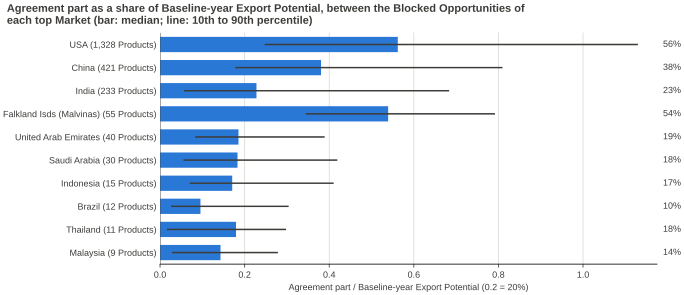

iso3,market,blocked_opportunities,share_min,share_p10,share_median,share_p90,share_max,order_correlation,top_shared,first_by_value,first_by_share
str,str,u32,f64,f64,f64,f64,f64,f64,u32,str,str
"""USA""","""USA""",1328,0.025978,0.247263,0.562066,1.129683,3.837697,-0.134626,0,"""Turbines: parts of turbo-jets …","""Vehicles: spark-ignition inter…"
"""CHN""","""China""",421,0.00523,0.177686,0.380557,0.809612,5.393105,-0.055454,0,"""Turbo-jets: of a thrust exceed…","""Cereals: wheat and meslin, oth…"
"""IND""","""India""",233,0.000167,0.056566,0.227977,0.683558,1.906726,0.07646,0,"""Turbo-jets: of a thrust exceed…","""Copper: tubes and pipes, of re…"
"""FLK""","""Falkland Isds (Malvinas)""",55,0.204587,0.344517,0.539273,0.791877,1.247698,0.23355,2,"""Iron or steel: articles n.e.c.…","""Printed matter: books, brochur…"
"""ARE""","""United Arab Emirates""",40,0.029552,0.082975,0.185409,0.389199,0.459774,-0.266979,1,"""Vehicles: spark-ignition inter…","""Lifts and skip hoists"""
"""SAU""","""Saudi Arabia""",30,0.012744,0.055375,0.183151,0.41909,0.836149,-0.170189,3,"""Vehicles: spark-ignition inter…","""Ferrous products: obtained by …"
"""IDN""","""Indonesia""",15,0.035745,0.069959,0.170627,0.410464,0.468219,0.175,7,"""Vehicles: dumpers, designed fo…","""Whiskies"""
"""BRA""","""Brazil""",12,0.001355,0.026149,0.095522,0.304008,0.315813,0.272727,8,"""Turbines: parts of turbo-jets …","""Turbines: parts of turbo-jets …"
"""THA""","""Thailand""",11,0.000516,0.016071,0.179568,0.297813,0.622106,-0.6,9,"""Vehicles: for transport of per…","""Vehicles: compression-ignition…"


In [40]:
display(reporting.agreement_part_variation_chart(bundle))
reporting.agreement_part_variation(bundle)

It is far from constant. Between the 10th and 90th percentile Products the share runs from 25% to 113% in the USA (median 56%), 18% to 81% in China and 6% to 68% in India. Sorting by it reorders each list: its rank correlation with the order by value lies between −0.27 and +0.23 in the five largest Markets, and none of the ten largest by value in the USA, China or India is among their ten largest by share. So the model associates an average agreement with rises that differ widely between Products in one Market: an association learned from other Exporters' trade, not evidence that an agreement acts Product by Product.

### Beside the PPML benchmark

The monotone constraint fixes the *direction* of a Scenario Effect: adding an agreement never lowers Export Potential. Its *size* is only what the trees learned, so it is set beside the method trade economists use: a structural gravity regression fitted by Poisson pseudo-maximum likelihood (PPML, `exportspredictor.ppml`), fitted once and saved with the artefact. Flows are summed to Sector level for 2012, 2015, 2018, 2021 and 2024, three years apart so that trade can adjust:

$$\text{Flow}_{e,i,s,t} = \exp\big(a_{e,s,t} + b_{i,s,t} + c_{e,i,s} + \beta\,\text{TradeAgreement}_{e,i,t}\big)\cdot\varepsilon.$$

The pair effects $c_{e,i,s}$ absorb everything fixed about a pair, including the fact that countries that sign agreements already trade a lot, so $\beta$ is identified only by pairs whose status changed, each compared with itself; $e^{\beta}-1$ is the change the regression associates with an agreement. It is a benchmark only: its pair effects need a pair's own Flows, which a held-out UK pair does not have (ADR 0001), so it could never serve Export Potential (*Course:* linear regression and reading its coefficients, taken further: a log link and Poisson loss so that zeros stay in, fixed effects as a very large one-hot encoding swept out by alternating projections, and standard errors clustered by pair). The model's side is read from the Blocked Opportunity values of every UK pair without an agreement, on the served Model Form. The published estimates are listed with their sources in `docs/research/rta-effects.md`.

In [41]:
reporting.ppml_benchmark(bundle)

estimate,coefficient,effect_pct,low_pct,high_pct,source
str,f64,f64,f64,f64,str
"""PPML benchmark: 3-way fixed ef…",0.050128,5.140596,-0.44273,11.037045,"""fitted once and saved with the…"
"""Model: Trade Agreement Scenari…",0.29888,34.834818,null,null,"""Blocked Opportunity values, 67…"
"""Model: Trade Agreement Scenari…",0.346928,41.471474,null,null,"""same pairs, each weighted equa…"
"""Yotov et al. (2016): PPML, Exp…",0.191,21.045945,null,null,"""Advanced Guide, ch. 1, Table 3…"
"""Head & Mayer (2014): median of…",0.28,32.312981,null,null,"""Handbook of International Econ…"
"""Head & Mayer (2014): mean of 1…",0.36,43.332941,null,null,"""Handbook of International Econ…"
"""Head & Mayer (2014): median of…",0.47,59.999419,null,null,"""Handbook of International Econ…"
"""Yotov et al. (2016): PPML with…",0.557,74.542835,null,null,"""Advanced Guide, ch. 1, Table 3…"
"""Baier & Bergstrand (2007): an …",0.693147,100.0,null,null,"""J. Int. Econ. 71(1), abstract"""


Three readings, all associational.

- **The benchmark is small**: about +5%, with a 95% interval that only just includes zero, below the whole published range (+21% to +100%). The reasons are known: BACI has no intra-national Flows, which more than double the estimate in the WTO/UNCTAD *Advanced Guide*; and many agreements join partners that already trade on low tariffs.
- **The served model's association is about seven times larger**: +35% weighted by Baseline Export Potential over 678,216 UK pairs, re-read from this artefact's values. It lies inside the published range but far outside the benchmark's interval on the same Flows and years.
- **Why the model sits high.** The trees learn the agreement association *across* pairs, and the other features cannot absorb everything that makes pairs with agreements close. The benchmark compares each pair with itself; a held-out UK pair has no pair effect, so the model cannot. Part of what it attributes to an agreement is the closeness of the countries that sign one, the endogeneity Baier and Bergstrand (2007) warn about.

### Beside the Event Backtests

A benchmark is still a model. An **Event Backtest** checks a Scenario Effect against an agreement that really happened (`exportspredictor.backtests`). The primary one is the **EU–Japan Economic Partnership Agreement**, in force from 1 February 2019:

1. Train one model on 2012–2018 only. A test multiplies every Flow from 2019 on by 1,000 and checks that the trained model does not change.
2. Predict EU–Japan Flows for 2019–2021 with the agreement on and off. The difference is the model's Scenario Effect.
3. Measure what happened with a **difference-in-differences**: the change in EU exports to Japan from 2016–2018 to each later year, against the change to ten **Control Markets**, large high-income Markets with no EU agreement in the window, with a 95% interval from resampling Products (*Course:* beyond the notes; it takes the counterfactual test from the model to the observed data).

COVID disrupted 2020 and 2021 unevenly, so 2019 is the cleanest year. A secondary backtest uses the UK–Australia and UK–New Zealand agreements (in force May 2023), scored by the test-year fold models, with provisional 2024 as its only post year. Both measure the model alone, before the Blend.

The EU–Japan Economic Partnership Agreement (in force 1 February 2019), with a model trained only on 2012–2018: For EU exports to Japan in 2019–2021, the model associated the agreement with +33% in Export Potential; the observed difference-in-differences against 10 similar Markets without an agreement was +2% (95% interval -7% to +14%). The model's effect is larger than what was observed, outside the interval. For Japan's exports to the EU in 2019–2021, the model associated the agreement with +46% in Export Potential; the observed difference-in-differences against 10 similar Markets without an agreement was -0% (95% interval -10% to +10%). The model's effect is larger than what was observed, outside the interval.


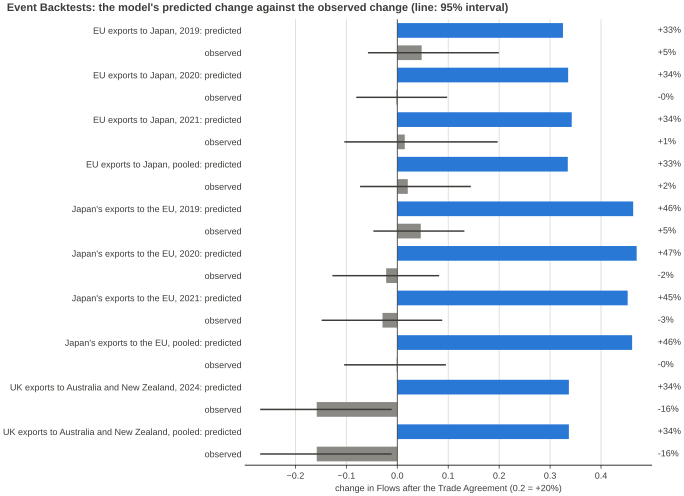

In [42]:
backtest = report.get("event_backtest")
print(f"Event Backtests: {NOT_RUN}." if backtest is None else backtest["text"])
reporting.event_backtests(bundle)

**Conclusion.** Scenarios change only policy columns, and the monotone constraint makes every added agreement raise Export Potential: the direction is designed in; the size is not. After EU–Japan the model alone associated +33% with EU exports to Japan where +2% was observed (95% interval −7% to +14%); the Blend would serve +22%, still outside it. For UK–Australia and New Zealand, +34% met an observed fall of 16%. The PPML benchmark associates an agreement with +5%, against the served model's +35%. Market Reach scales a pair with and without a Scenario alike, so it changes none of these shares (ADR 0010). The 2,169 Blocked Opportunities with room to grow ($18.5bn) rest mostly on the agreement flag: the model ties 31% of their value to the tariff, and the rest varies widely between Products in a Market. So Scenario Effects and Blocked Opportunity values are **Illustrative**: where the model associates an agreement with most trade, an upper-end order of magnitude, never a forecast. The app, the API and the model card carry the same Scenario note.

## 9. Explaining Export Potential

An Advisor who takes an Opportunity to a firm must say *why* the model expects more trade. This section shows what drives Export Potential overall and why one pair scores as it does (*Course:* explainability, global against local, and SHAP for local explanations that are additive and faithful to the model you ship).

XGBoost computes exact TreeSHAP values itself, so no background sample is needed. Each pair is explained by **its own fold model**, the one that held it out and scored its Baseline (ADR 0001): any other model would explain a number the Advisor never sees. The Blend is explained as it is served: the model's SHAP values are scaled by its weight, 0.7, and the Naive Baseline's share is attributed half to UK supply and half to Market demand, its two inputs (`prediction.log_contributions`). Contributions add up on the log scale, so the base value plus every contribution reproduces the Export Potential exactly (`tests/test_explain.py`), and on the dollar scale each factor multiplies Export Potential by `exp(contribution)`.

**Global importance** is the mean absolute contribution over a random sample of 2,000 Baseline pairs. Unlike impurity importance, it is measured on the served predictions and cannot credit a feature the model never uses (*Course:* feature importance, impurity against permutation). A sample of 20,000 gave the same top five and moved no feature by more than about 2%, at ten times the run time.

In [43]:
from exportspredictor import explain

importance = explain.global_importance(bundle, sample=2_000)  # about 80 s on the CPU with the depth-12 fold models
importance.with_columns(typical_multiplier=pl.col("mean_abs_contribution").exp())

feature,label,mean_abs_contribution,pairs,typical_multiplier
str,str,f64,i64,f64
"""log_demand_loo""","""How much the Market imports th…",1.361286,2000,3.901209
"""log_supply_loo""","""How much the UK exports this P…",1.093704,2000,2.985311
"""high_income_share_loo""","""Share of the Market's imports …",0.432566,2000,1.541208
"""log_distance""","""Distance from the UK to the Ma…",0.335679,2000,1.39889
"""log_gdp_d""","""Size of the Market's economy (…",0.312378,2000,1.366671
…,…,…,…,…
"""common_colonizer""","""the UK and the Market share a …",0.009784,2000,1.009832
"""efta_o""","""the UK is a member of EFTA""",0.009225,2000,1.009267
"""efta_d""","""the Market is a member of EFTA""",0.00778,2000,1.007811


On the served artefact, demand dominates: how much the Market imports the Product from others moves a typical pair by a factor of about 3.9, and UK supply of the Product to other Markets by about 3.0. Both carry the Naive Baseline's share as well as the model's. Then come the high-income share of the Market's imports (×1.5), distance (×1.4) and the Market's GDP (×1.4). The bloc flags move a typical pair by about 1%: most pairs' policy status never changes, so Scenario Effects rest on a small part of the model, one more reason to read them as Illustrative. Low importance is also a governance signal (*Course:* mean |SHAP| supports data minimisation): the common-colonizer feature adds about 1% and could be dropped at no cost, while the bloc flags stay because Scenarios need them.

**A local explanation.** The largest Opportunity is parts of turbo-jets and turbo-propellers (`841191`) to France. The Why? page shows the same factors in the same words:

In [44]:
top_opportunity = baseline.sort("export_gap_usd", descending=True).row(0, named=True)
why = explain.explain_pair(bundle, top_opportunity["hs6"], top_opportunity["iso3"])
print(f"{top_opportunity['description'][:60]} to {why.market}: Export Potential {explain.usd(why.export_potential_usd)}, scored by fold model {why.fold}")
display(pl.DataFrame([{"factor": f.label, "value": f.value_text, "multiplier": f.multiplier} for f in why.factors[:8]]))
pl.DataFrame([{"year": point.year, "actual_exports_usd": point.actual_exports_usd} for point in why.history])

Turbines: parts of turbo-jets and turbo-propellers to France: Export Potential US$1.3 billion, scored by fold model 2


factor,value,multiplier
str,str,f64
"""How much the UK exports this P…","""US$12.5 billion""",200.526538
"""How much France imports this P…","""US$2.5 billion""",163.211084
"""How specialised the UK is in t…","""8.57× the world average share …",1.656171
"""Distance from the UK to France""","""344 km""",1.612625
"""Size of France's economy (GDP)""","""US$3.2 trillion""",1.234403
"""Size of the UK economy (GDP)""","""US$3.7 trillion""",1.195509
"""How much of this Product Franc…","""Exports 378% of what it import…",1.110802
"""The tariff France charges on t…","""0%""",1.074378


year,actual_exports_usd
i64,f64
2019,8.5219805e7
2020,1.28789098e8
2021,1.02281755e8
2022,1.06717221e8
2023,1.00891032e8
2024,8.3759177e7


The served 2024 Export Potential for UK turbo-jet parts in France is about $1.3bn, from fold model 2, against Actual Exports near $0.1bn in every year since 2019. The factors read as an Advisor would want: the UK exports $12.5bn of this Product to other Markets, France imports $2.5bn of it from others, the UK is 8.6 times as specialised in it as the world average, and France is close. One factor is a warning: France *re-exports* 378% of what it imports of these parts. Actual Exports have not moved; section 10 reads this pair as an error.

Two limits apply to every explanation. SHAP values are **associations inside the model**: "distance lowers Export Potential" means comparable distant pairs trade less, not that distance causes it. And the largest factors (a Market's size, its imports, distance) are not things an Advisor can change; the actionable reading is the supply side, that the UK already sells this Product well elsewhere (*Course:* actionable explanations).

**Conclusion.** Every Export Potential decomposes exactly into named factors from the fold model that produced it, in words an Advisor can repeat. Globally the served model is driven by what Markets buy and what the UK sells, which is also what the Naive Baseline knows; policy features carry a small part of each prediction. A local explanation read beside the Actual Exports history is the Advisor's main defence against a misleading Opportunity.

## 10. Limits and governance

A result is only as useful as its stated limits. This section reads the known limitations, a sanity check of the top Opportunities and the finding that removed the Uncertain Opportunity badge. It then gives one short entry per governance topic of the course, each pointing to the artefact that is its evidence, and leaves the rest to the model card (*Course:* responsible AI as design constraints with owners and evidence: a commitment without an artefact is an aspiration).

### Known limitations

These are served by the API and shown on the app's Model Evaluation page, so that Advisors can caveat their briefings. Two weigh most: every Applied Tariff after 2021 is carried forward (ADR 0006), and sanctions, prohibitions and other non-tariff barriers are invisible to the model.

In [45]:
with pl.Config(fmt_str_lengths=200, tbl_rows=20):
    display(pl.DataFrame(evaluation.LIMITATIONS))

title,text
str,str
"""Goods only""","""The model covers goods trade only. Services, about half of UK exports, are not in the data."""
"""Tariffs carried forward from 2021""","""Applied Tariffs come from UNCTAD TRAINS, which ends in 2021. 2022–2024, the test year and the whole Gap Period included, reuse each pair's 2021 rate, or 0 where a Trade Agreement entered force after 2…"
"""Excluded Products""","""Crude and refined oil, gas, coal and electricity, bullion and coins, precious-metal scrap, antiques and radioactive elements are Excluded Products: their trade follows pipelines, bullion markets or li…"
"""Trained on the top 100 Exporters""","""The model trains on Flows from the top 100 economies by mean GDP over 2012–2023, the UK always included, into every Market; other Exporters' rows are sampled to fit the GPU. Smaller Exporters still co…"
"""Values are nominal US dollars""","""Every value is in nominal US dollars, as BACI reports it, with no adjustment for inflation or exchange rates. A change between years mixes real trade growth with price and currency movements."""
"""What the Potential Range assumes""","""The Potential Range is calibrated on other Exporters' 2024 Flows, never the UK's, so it assumes UK pairs vary around their Export Potential as comparable pairs of other top-100 Exporters do (exchangea…"
"""Associations, not causes""","""Export Potential and Scenario Effects are associations the model has learned from global trade. ""The model associates a Trade Agreement with +X%"" does not mean the agreement causes +X%, and an Opportu…"
"""Provisional 2024 data""","""The Baseline year, 2024, is provisional in BACI: some countries had not reported when it was built, and it will be revised in the next release. 2024 has about 5% fewer Flows than 2023."""
"""The 2012 product edition""","""Products use HS 2012 codes (BACI's HS12 revision, chosen for its longer history). A few HS6 codes Advisors know from current tariff schedules (HS 2017 or 2022) differ or are split."""


### Sanity check: the top Opportunities

A model can score well and still rank nonsense, so the largest Export Gaps are read as a trade economist would read them. No Excluded Product may appear at all (ADR 0005). Flagged Products and Re-export Hubs stay in the rankings with a caveat, so the share of the top of the list they hold is measured, beside the share of Uncertain Opportunities used below. Then whisky (`220830`), a Product an Advisor knows well.

In [46]:
from exportspredictor.exclusions import is_excluded

top_opportunities = baseline.filter(pl.col("export_gap_usd") > 0).sort("export_gap_usd", descending=True)
display(top_opportunities.select(
    "hs6", "description", "market", "opportunity_type", "export_potential_usd", "actual_exports_usd", "export_gap_usd",
).head(10))
pl.concat(
    [
        top_opportunities.head(top).select(
            top=pl.lit(top),
            excluded_products=is_excluded().sum(),
            flagged_product_share=pl.col("flagged_product").mean(),
            reexport_hub_share=pl.col("reexport_hub").mean(),
            uncertain_share=pl.col("uncertain_opportunity").mean(),
        )
        for top in (20, 100, 1000)
    ]
)

hs6,description,market,opportunity_type,export_potential_usd,actual_exports_usd,export_gap_usd
str,str,str,str,f64,f64,f64
"""841191""","""Turbines: parts of turbo-jets …","""France""","""Expand""",1.0916e9,9.7122e7,9.9452e8
"""841112""","""Turbo-jets: of a thrust exceed…","""Germany""","""Expand""",1.2046e9,4.59537415e8,7.4503e8
"""300490""","""Medicaments: consisting of mix…","""France""","""Expand""",1.1187e9,3.9579e8,7.2294e8
"""870323""","""Vehicles: spark-ignition inter…","""USA""","""Expand""",1.8337e9,1.2522e9,5.8141e8
"""841112""","""Turbo-jets: of a thrust exceed…","""China""","""Expand""",8.7006e8,3.2030e8,5.4976e8
"""841112""","""Turbo-jets: of a thrust exceed…","""Ireland""","""Expand""",8.0111e8,3.10911226e8,4.9019e8
"""841191""","""Turbines: parts of turbo-jets …","""USA""","""Expand""",1.8872e9,1.4531e9,4.3408e8
"""300210""","""Blood, human or animal, antise…","""Germany""","""Expand""",7.0462e8,2.7117e8,4.3344e8
"""870390""","""Vehicles: for transport of per…","""Netherlands""","""Expand""",6.9170e8,2.67538645e8,4.2416e8


top,excluded_products,flagged_product_share,reexport_hub_share,uncertain_share
i32,u32,f64,f64,f64
20,0,0.05,0.25,0.6
100,0,0.06,0.32,0.56
1000,0,0.057,0.357,0.844


In [47]:
baseline.filter(pl.col("hs6") == "220830").sort("export_gap_usd", descending=True).select(
    "market", "export_potential_usd", "actual_exports_usd", "export_gap_usd"
).head(8)

market,export_potential_usd,actual_exports_usd,export_gap_usd
str,f64,f64,f64
"""Netherlands""",4.6567e8,1.32187358e8,3.3348e8
"""Ireland""",1.0108e8,1.6492e7,8.4584e7
"""Italy""",1.0483e8,8.4291e7,2.0538e7
"""Belgium""",6.3902e7,4.8087e7,1.5815e7
"""Czechia""",3.1743e7,1.5942504e7,1.5801e7
"""Denmark""",3.6888e7,2.4426e7,1.2462e7
"""China, Hong Kong SAR""",5.1983e7,3.9729156e7,1.2254e7
"""Saudi Arabia""",7.1703e6,718.666667,7.1696e6


On the served artefact no Excluded Product appears. Flagged Products hold 5% of the top 20 and 6% of the top 1,000. Re-export Hubs (Hong Kong, Ireland, Belgium, the Netherlands) hold about a third of the top 100 and of the top 1,000, which is why their rows carry a caveat. The top Opportunities are plausible: aero-engines and their parts (France, Germany, China, Ireland, the USA), packaged medicines (France) and cars to the USA, all *Expand* pairs in the UK's known strengths. Whisky shows what Market Reach changed: the **Russian Federation**, fourth before it, now has no Export Gap, because the UK's reach into Russia collapsed under sanctions from 2022. No feature records sanctions themselves, so such rows are not removed but marked, as the next table shows.

### Sanctioned Markets and Restricted Pairs

Two Caveat Tiers mark what no feature records (ADR 0005). A **Sanctioned Market** is under broad UK trade sanctions in the Baseline year: Russia and Belarus since 2022, North Korea, and Syria until its regime narrowed in 2025. A **Restricted Pair** is a Product the Market prohibits outright: alcoholic beverages into Saudi Arabia, Kuwait, Libya and Iran. Both lists are hand-kept, dated tables in `exportspredictor.restrictions`, each entry with its source, read by the pipeline, the API and the app alike (*Course:* policy as data, extended from a prompt's rules to a model's outputs). They are caveats, not exclusions: scores, rankings and metrics are unchanged, and leaving Russia and Belarus out of the 2022 Selection Measure would move it by only +0.003, while an Advisor who never sees them cannot explain why they are closed. Each row names its regime and start year, or what the Market prohibits, and each tier has a hide filter. The Opportunities each tier covers, overall and in the top 100, 1,000 and 10,000:

In [48]:
reporting.caveat_tier_reach(bundle)

Caveat Tier,Opportunities,in top 100,"in top 1,000","in top 10,000"
str,i64,i64,i64,i64
"""Flagged Product""",221312,6,57,471
"""Re-export Hub""",28961,32,357,2851
"""Sanctioned Market""",19042,0,0,7
"""Restricted Pair""",49,0,0,2
"""Offset Pair""",246790,21,159,1709


On the served artefact, Sanctioned Markets hold about 19,000 Opportunities ($0.08bn of Export Gap), none of the top 1,000 and 7 of the top 10,000: Market Reach has already lowered them. Restricted Pairs hold 49; the highest is whisky to Saudi Arabia, at #2,249. Few rows, but each would mislead an Advisor who took it at face value.

### Offset Pairs: reading the two largest errors

The two largest Opportunities were read as errors (*Course:* error analysis: sort errors before fixing them, as only real mistakes yield to modelling; extended here from labels to where trade is recorded). Turbine parts to France and turbo-jets to Germany share **Heading** 8411. Over the Heading, Export Potential is close to Actual Exports in both Markets (the table, $m), but France buys engines and Germany parts, and the model spreads each total across both. It is right about the Heading and wrong about the split, which no feature may see without reading the UK's own trade with that Market. So the answer is a fifth Caveat Tier (ADR 0005): an **Offset Pair** is an Opportunity whose Export Gap the rest of its Heading offsets by at least half, with a caveat that the gap may be trade recorded under a neighbouring Product. Its reach, from the artefact metadata:

In [49]:
display(reporting.heading_split(bundle, products=("841112", "841191"), markets=("FRA", "DEU")))
print(reporting.offset_pair_reach(bundle))

Market,Figure,841112 ($m),841191 ($m),Whole Heading 8411 ($m)
str,str,f64,f64,f64
"""France""","""Actual Exports""",1761.4,97.1,1939.5
"""France""","""Export Potential""",687.5,1091.6,1914.7
"""France""","""Export Gap""",-1073.9,994.5,-24.8
"""Germany""","""Actual Exports""",459.5,1423.7,2037.0
"""Germany""","""Export Potential""",1204.6,603.5,2013.3
"""Germany""","""Export Gap""",745.0,-820.1,-23.7


Offset Pairs: 246,790 of 898,686 Opportunities (27%); 21 of the top 100, 159 of the top 1,000 and 1,709 of the top 10,000; $19.0bn of $97.7bn of positive Export Gap (19%).


### Volatile and one-off Flagged Products

Some Products are sold in a few large, irregular contracts, so a year's Flows record timing more than lasting demand. The open review (`docs/research/open-review-2022.md`, section 6) measured the volatility of UK exports of each Product over 2012–2021 and found the 2022 Selection Measure falls with it: 0.76 for the calmest fifth of Products, then 0.68, 0.59 and 0.49, and 0.30 for the lumpiest fifth.

Flagged Products therefore gain a volatility rule (ADR 0005). A Product's volatility is the standard deviation of the year-to-year log change of UK exports of it over the training years, those before the validation year, so neither the validation, the test nor the Baseline year decides which Products are flagged (*Course:* data leakage, extended from the features to the caveats). Products above the 80th percentile are flagged as volatile, and the one-off Products the review named (banknotes and stamps, aircraft, vessels and platforms, precious-metal compounds) as one-offs when the rule misses them. Each row's caveat names its reason, and, as for every tier, no score, ranking or metric changes. The Flagged Products by reason, then the rule's years and threshold:

In [50]:
display(reporting.flagged_products_by_reason(bundle))
{key: bundle.metadata["volatile_products"][key] for key in ("years", "share", "threshold")}

Reason,Products,Opportunities
str,u32,i64
"""volatile: UK exports swing wid…",1018,214930
"""Sector 71: precious stones and…",32,5838
"""one-off: few, large contracts""",3,544


{'years': [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021],
 'share': 0.2,
 'threshold': 0.7339117321000903}

On the served artefact the rule flags 1,018 Products outside Sector 71 as volatile (a volatility above 0.73) and three more as one-offs: banknotes and stamps (490700), light helicopters (880211) and precious-metal compounds (284390). With the 32 Sector 71 Products, 1,053 of the 5,138 Products are Flagged Products, and Flagged Products now hold 57 of the top 1,000 Opportunities, against 20 before. On the 2022 ranking, the Products the rule flags score 0.30 on average against 0.63 for the others (the open review's per-Product correlations), so the flag marks where the ranking is weakest. Their gaps are better read as timing than as lasting potential.

### The Potential Range and the Uncertain Opportunity share

Each UK pair has a **Potential Range**: the range within which Actual Exports fall 80% of the time for pairs of about the same Export Potential (ADR 0007). It is split conformal prediction, calibrated on other Exporters' 2024 rows, never the UK's (a UK residual is its Export Gap with the sign flipped), within 20 bands of Export Potential (Mondrian bands, because Tweedie errors grow with the prediction; a band spanning more than tenfold is split at $10m, $100m and $1bn, so a $1bn pair is compared with large pairs), with coverage checked on a held-out half of the rows (*Course:* held-out validation, extended from one error figure for the model to a range for each prediction with a coverage guarantee). An Opportunity whose Actual Exports lie inside its range is an **Uncertain Opportunity**: its Export Gap is within the scatter normally seen among comparable pairs. The finding, printed from the evaluation report, then coverage by band and by size of Export Potential:

In [51]:
from exportspredictor import conformal

potential_range = report["potential_range"]
print(conformal.coverage_text(potential_range))
pl.DataFrame(potential_range["by_band"])

On a held-out half of the calibration rows (6,392,004 other Exporters' rows), 85% of their Actual Exports fell inside their Potential Range, against a target of 80%. 822,386 of the 898,686 Opportunities (92%) have UK Actual Exports inside their Potential Range (Uncertain Opportunities): most Export Gaps are within the variation normally seen among comparable pairs, so an Export Gap says where to look rather than proving an Opportunity. Over every UK pair, 74% of UK pairs have Gap Period Actual Exports inside their Potential Range (81% without Market Reach).


band,min_export_potential_usd,rows,coverage
i64,f64,i64,f64
0,0.0,318681,0.897675
1,4.584439,320407,0.893014
2,32.418272,318930,0.877977
3,137.969409,320225,0.848319
4,395.834911,318891,0.806649
…,…,…,…
17,326572.318208,319657,0.801005
18,676736.517456,319528,0.796088
19,1.9626e6,235396,0.798149


In [52]:
pl.DataFrame(potential_range["by_size"])

size,min_export_potential_usd,rows,coverage
str,f64,i64,f64
"""under $2m""",0.0,6076663,0.850713
"""$2m–10m""",2e6,231188,0.798218
"""$10m–100m""",1e7,77450,0.805024
"""over $100m""",1e8,6703,0.804691


Coverage on the held-out half is 85% against the 80% target, and within half a point of 80% for every size above $2m. The excess sits in the smallest bands, where most Actual Exports are exactly $0 and ties widen the range; from an Export Potential of about $900 upwards every band is within half a point of 80%. On UK pairs it is lower, 74% (81% without Market Reach), because Market Reach scales UK pairs and not the calibration rows; that gap below the target is stated as a known limitation.

**92% of Opportunities are Uncertain Opportunities**, and so are 84% of the top 1,000 by Export Gap (the sanity check above). Most positive gaps are the small gaps of *New Market* pairs, well inside the ordinary scatter, and most of the largest gaps are inside it too: pairs above $100m vary from about 28% to three times their Export Potential. Splitting the top band by size narrowed that from 1%, the scatter of $2m pairs, so France turbine parts reads $307m to $3.5bn instead of $8.4m to $2.6bn. A badge on nine rows in ten separated nothing, so it was removed from the ranking pages. The share is reported here, on the Model Evaluation page and in the model card, and each pair's range stays on the Why? page (ADR 0007, Outcome). The offsets are ratios of Export Potential (ADR 0007 amended).

### Model card

The course asks for a short card covering intended and out-of-scope use, owner, metrics by group, limitations and data sources, generated from code and versioned with the model, printing UNASSIGNED rather than omitting a section. `governance.model_card` builds it from the artefact, so its numbers are the evaluated ones, and it leads as this notebook does: the headline, the Model Form, the Illustrative Scenario note, how the form was chosen and the Potential Range share, with the frozen results last. The pipeline writes it into each artefact folder; a real run reads it, and the fixture run writes its own. Below is its headline and its list of sections; the rest is in the card file. The owner is **UNASSIGNED** on purpose: naming who answers for the model is a decision for the team that adopts it.

In [53]:
from IPython.display import Markdown

from exportspredictor import governance

# The fixture run saves its own artefact and card; the real ones were written by the pipeline and are only read here.
saved_to = artefacts.save(bundle, artefacts_dir()) if FIXTURE_MODE else artefacts_dir() / bundle.version
card_path = governance.write_model_card(bundle, saved_to) if FIXTURE_MODE else saved_to / governance.MODEL_CARD_FILE
Markdown(reporting.model_card_excerpt(card_path))

**Model card: UK Exports Predictor, version 20261122T133316Z**

An excerpt. The whole card is `20261122T133316Z/model_card.md` in the artefacts directory, written with the artefact.

## Headline

**On 2023, read once, the UK ranking of this version is 0.600 on the tie-proof Selection Measure and 0.600 on the old measure (where tied predictions share their average rank): it beats the Naive Baseline (0.514 tie-proof and 0.523 old, from every Exporter's Flows; 0.523 old, as reported for v2). Earlier versions on the old measure: Blend 0.555, v2 0.511, v1 0.540; on the tie-proof measure, from their saved scores: Blend 0.555, v2 0.511, v1 0.540. These are associations on one test year, not a forecast.**

| Version | UK ranking, old measure | UK ranking, tie-proof | Size-matched Lift | Lift | Tweedie deviance, all Exporters | Tweedie deviance, UK pairs |
| --- | --- | --- | --- | --- | --- | --- |
| This version (Blend with Market Reach) | 0.600 | 0.600 | 0.75 | 4.29 | 468.5 | 2,537.4 |
| Blend | 0.555 | 0.555 | 0.76 | 4.99 | 433.8 | 566.3 |
| v2 | 0.511 | 0.511 | 0.79 | 5.23 | 355.5 | 568.6 |
| v1 | 0.540 | 0.540 | 0.83 | 5.80 | n/a | n/a |
| Naive Baseline, every Exporter's Flows (this run) | 0.523 | 0.514 | | | | |
| Naive Baseline as reported for v2 (training rows' Flows) | 0.523 | n/a | | | | |

The same tie-proof ranking on the Markets that import the most (no choice was made on these):

| Version | 30 largest Markets | 60 largest Markets |
| --- | --- | --- |
| This version (Blend with Market Reach) | 0.570 | 0.604 |
| Blend | 0.512 | 0.537 |
| v2 | 0.538 | 0.556 |
| v1 | 0.509 | 0.542 |
| Naive Baseline, every Exporter's Flows (this run) | 0.355 | 0.396 |

Choosing on the ranking traded away accuracy on size: Tweedie deviance over all Exporters is 468.5 for this version against 433.8 for Blend (lower is better), so the size of Export Potential is estimated less well. Size-matched Lift is 0.75 (Blend 0.76). Treat dollar values with more caution than rankings.

**Its sections:** Headline; Model Form; Illustrative Scenario Effects; Blocked Opportunities; What Market Reach changes; How the Model Form was chosen; Potential Range; Metrics; Parts not run; Limitations; Intended use; Out-of-scope use; Training scope and sampling; Features; Excluded Products; Bias review: Potential Range coverage by Exporter; Data sources; Source versions; Decisions behind the model; Frozen results.

### Data lineage

Every served number should trace back to exact inputs (*Course:* data lineage and reproducible artefacts). Raw downloads are fingerprinted with their size and SHA-256 (`governance.data_lineage`). Every derived table is rebuilt by one command, in the order of `scripts/rebuild.py`. Each artefact is a folder named by its UTC timestamp, whose metadata records the BACI release, the Exporter scope, the sampling rates and seed, the parameters, the XGBoost version and the device, and, for a version derived from another without retraining, which one: `ppml_benchmark_from` for the PPML benchmark, `blocked_values_from` for the Tariff part (the served one), `copied_from` for the other steps. A derived version keeps its source's `created_at`, when the models were trained (*Course:* registry versions). The API serves the newest complete folder, so rolling back means removing it. One gap remains: the artefact does not yet store the raw-file hashes, so proving which download a version was trained on relies on the data folder not having changed.

In [54]:
if FIXTURE_MODE:
    print("Fixture mode: the fixture world is generated in code (exportspredictor.fixture), so there are no raw files to fingerprint.")
else:
    lineage = governance.data_lineage()  # hashes about 2.8 GB of downloads, under a minute
    display(lineage.group_by("source").agg(files=pl.len(), bytes=pl.col("bytes").sum()).sort("source"))
    display(lineage.filter(pl.col("source").is_in(["UNCTAD TRAINS", "UN HS concordances"])))
{
    **{key: bundle.metadata.get(key) for key in (
        "version", "source", "xgboost_version", "device", "zero_sampling_rate", "uk_zero_sampling_rate",
        "zero_sampling_seed", "non_uk_sampling_rate", "created_at", "copied_from", "ppml_benchmark_from",
    )},
    "exporters_in_scope": len(bundle.metadata.get("exporter_scope") or []),
}

source,files,bytes
str,u32,i64
"""BACI HS12 V202601 (CEPII)""",4,1268530150
"""CEPII Gravity V202211""",5,1458141032
"""HMRC OTS 2023 and UN HS concor…",2,36393610
"""IMF World Economic Outlook""",2,308389
"""UN HS concordances""",2,896843
"""UNCTAD TRAINS""",1294,61413650
"""WTO RTA-IS""",1,207439
"""World Bank WDI""",3,1541836
"""World Bank country list""",1,113954


source,file,bytes,sha256
str,str,i64,str
"""UNCTAD TRAINS""","""raw/trains/2012/ABW.parquet""",14767,"""fc94b324f3cba023b117ac9669546a…"
"""UNCTAD TRAINS""","""raw/trains/2012/AFG.parquet""",16294,"""b3e2e95e9c065d4c406ca84a30d217…"
"""UNCTAD TRAINS""","""raw/trains/2012/AGO.parquet""",15028,"""97f0edbc48b2ae43b69c91d46c9fc0…"
"""UNCTAD TRAINS""","""raw/trains/2012/AIA.parquet""",14790,"""7daaafd69c3e0871a62178a4504bf7…"
"""UNCTAD TRAINS""","""raw/trains/2012/ALB.parquet""",43916,"""6a7b9357f431937a878ddac8b04e4f…"
…,…,…,…
"""UNCTAD TRAINS""","""raw/trains/availability.xml""",2125532,"""271d5ed9ba9a7d9111877011ca79a4…"
"""UNCTAD TRAINS""","""raw/trains/countries.xml""",116491,"""6ce9747d24d4c53897d8f455a664d8…"
"""UNCTAD TRAINS""","""raw/trains/manifest.json""",250,"""653f208bf8d9ba797b29002c141419…"


{'version': '20261122T133316Z',
 'source': 'BACI V202601',
 'xgboost_version': '3.4.1',
 'device': 'cuda',
 'zero_sampling_rate': 0.05,
 'uk_zero_sampling_rate': 1.0,
 'zero_sampling_seed': 0,
 'non_uk_sampling_rate': 0.5894,
 'created_at': '2026-11-20T22:17:26.555965+00:00',
 'copied_from': None,
 'ppml_benchmark_from': None,
 'exporters_in_scope': 100}

### Bias review

Bias here concerns countries and Sectors, not people: the model holds no personal data. BACI is built from what countries report, and poorer countries report later and less completely, so absent Flows read as zeros make a poorly reporting Market look as if it buys little (data bias). One loss, dominated by large Flows, serves every Market (objective bias). The review is a representation audit and a worst-group evaluation on the UK's 2023 out-of-fold grid, by region and by World Bank income level as a stand-in for reporting quality; a group with fewer than 500 UK Flows is flagged thin (*Course:* representation audit, and evaluating beyond the average).

In [55]:
uk_accuracy = report["accuracy"]["uk_out_of_fold"]
bias_columns = ["group", "rows", "non_zero_flows", "actual_usd", "model_spearman_within_product", "naive_spearman_within_product"]
for breakdown in ("by_region", "by_income"):
    if uk_accuracy.get(breakdown):
        display(pl.DataFrame(uk_accuracy[breakdown]).select(bias_columns).with_columns(thin=pl.col("non_zero_flows") < 500))
pl.DataFrame(uk_accuracy["by_sector"]).select(bias_columns).head(5)  # the weakest Sectors (HS chapters)

group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product,thin
str,i64,i64,f64,f64,f64,bool
"""Latin America & Caribbean""",200382,40883,9.6724e9,0.433746,0.302582,false
"""Unclassified""",87346,2947,1.47759136e8,0.45638,0.034655,false
"""Sub-Saharan Africa""",246624,48109,6.3658e9,0.466414,0.349007,false
"""Middle East, North Africa, Afg…",118174,39716,2.5255e10,0.58573,0.416307,false
"""East Asia & Pacific""",195244,48692,6.0684e10,0.645071,0.601117,false
"""South Asia""",30828,8654,6.7134e9,0.69654,0.547087,false
"""Europe & Central Asia""",262038,126883,1.8306e11,0.70428,0.557927,false
"""North America""",15414,9792,6.1406e10,0.828696,0.802199,false


group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product,thin
str,i64,i64,f64,f64,f64,bool
"""Low income""",128450,12804,1.0545e9,0.395251,0.233258,false
"""Unclassified""",87346,2947,1.47759136e8,0.45638,0.034655,false
"""Lower middle income""",241486,48854,1.4618e10,0.486901,0.355186,false
"""Upper middle income""",298004,81534,4.4697e10,0.516735,0.426987,false
"""High income""",400764,179537,2.9279e11,0.691566,0.602488,false


group,rows,non_zero_flows,actual_usd,model_spearman_within_product,naive_spearman_within_product
str,i64,i64,f64,f64,f64
"""03""",42525,2280,2.4798e9,0.289693,0.25165
"""26""",8325,409,1.98877305e8,0.305858,0.260425
"""01""",7650,459,8.32025155e8,0.31208,0.257672
"""02""",14850,1368,2.2619e9,0.342403,0.298241
"""47""",4725,350,6.28650212e8,0.345191,0.301593


The gradient is steep: the served version ranks UK Markets at 0.69 in high-income Markets and 0.40 in low-income ones, and by region from 0.83 (North America) to 0.43 (Latin America and the Caribbean). It is mostly a data effect: in low-income Markets only about one UK pair in ten has any trade, so the rankings are among near-zero Flows that BACI measures least well. It beats the Naive Baseline in every group, and no group is thin. By Sector the weakest are commodities, such as ores, fish, live animals and wood pulp, where sanitary rules, quotas and logistics decide Markets and the model sees none of them; there the Naive Baseline often ranks better. The cost falls on developing Markets: an Advisor reading the rankings at face value would see fewer, noisier Opportunities there, for reasons of data quality rather than fundamentals. The mitigations in place are the region breakdown on the Model Evaluation page and a region filter on every ranking; per-group thresholds (*Course:* per-group thresholds) would come next if the rankings were used to allocate budgets.

### Regulation

**EU AI Act.** Intended purpose decides the tier, not the technique (*Course:* the EU AI Act's risk tiers). The purpose here is decision support for public export promotion, from aggregate trade statistics about countries and Products, never natural persons. The system is not prohibited and not high-risk (no Annex III use, not a safety component), and it neither talks to people as if human nor generates synthetic content, so it is **minimal risk**, with no new legal duties. **Function creep would change the tier**: scoring individual firms for grants would be a decision about specific businesses, so the model card lists it as out of scope.

**The UK approach** has no AI statute: regulators apply five principles, and the course asks for an artefact per principle. Safety and robustness: the time split, the leakage tests and the Event Backtests. Transparency: the Why? page and the model card. Fairness: the bias review. Accountability: versioned artefacts, ADRs and the decision log, with the owner still UNASSIGNED. Contestability: outputs are leads that Advisors decide on, each with its explanation. The data are country-level aggregates, so UK GDPR is not engaged.

### Drift

A trained model is frozen while trade moves (*Course:* model drift, its three types, and the Population Stability Index). **Data drift** is checked with each feature's PSI on the UK grid, 2023 against 2024: stable below 0.10, act above 0.20. **Concept drift**, the same fundamentals bringing different trade after new tariffs or sanctions, shows only as falling accuracy, so it needs the yearly re-evaluation. **Label drift** comes from BACI revising its provisional year. Then the stability of the rankings between the two years, scored by the same models:

In [56]:
if FIXTURE_MODE:
    last_year = feature_table.select(pl.col("year").max()).collect().item()
    drift_reference = feature_table.filter(pl.col("year") == last_year - 1).collect()
    drift_current = feature_table.filter(pl.col("year") == last_year).collect()
else:
    drift_reference = pl.read_parquet(feature_dir / "uk_grid_2023.parquet")
    drift_current = pl.read_parquet(feature_dir / "uk_grid_2024.parquet")
display(governance.feature_drift(drift_reference, drift_current, features.FEATURES))
print(report["stability"]["text"])

feature,psi,status
str,f64,str
"""log_gdp_o""",10.543652,"""act"""
"""log_population_o""",10.543652,"""act"""
"""relatedness""",0.243515,"""act"""
"""high_income_share_loo""",0.007534,"""stable"""
"""log_gdp_d""",0.00541,"""stable"""
…,…,…
"""eu_d""",0.0,"""stable"""
"""cptpp_o""",0.0,"""stable"""
"""efta_o""",0.0,"""stable"""


Scored by the same models, each Product's ranking of Markets by Export Potential in 2024 has a rank correlation of 0.98 with its 2023 ranking, and 72% of the top 1,000 Opportunities by Export Gap are the same in both years.


Every Market-side feature is stable. Three read *act*, for known reasons: the UK's own GDP and population take one value per year on the UK grid, so any change moves every row (PSI is the wrong test for a constant, which the clip ranges fitted on training years guard instead), and Relatedness, a UK-side feature, moves with the provisional 2024 export basket and is the one to watch. The Applied Tariff cannot drift because it is carried forward, which is a limit of the data, not evidence of stability. Rankings are broadly stable between 2023 and 2024, but only about seven in ten of the top 1,000 Opportunities are the same, another reason the Export Gap averages the Gap Period.

**The yearly refresh** follows each January's BACI release: rebuild, check the inputs (the HMRC cross-check and PSI), retrain with the test year moved on, promote only if the Naive Baseline is beaten, and use the 2025 data as the first live test of the CPTPP Scenario.

**Conclusion.** The limits are measured and stated where the numbers are read. The top Opportunities are plausible at the level of the Heading, but sanctions, prohibitions and the split within a Heading are invisible to the model. 92% of Opportunities, and 84% of the top 1,000, lie inside their Potential Range, so that share is reported as a finding instead of a badge that marked almost every row. The model ranks UK Markets much better where trade data are good, and Advisors are told so. Governance has an artefact for each course topic: a generated model card, fingerprinted inputs and versioned artefacts, a bias review, a minimal-risk classification with function creep ruled out of scope, and drift checks with a yearly refresh. The open gaps are named: no owner, raw-file hashes not stored in the artefact, and no per-region thresholds.

## 11. Conclusions

The question was whether a model trained on global trade can tell Advisors where to look first better than a market-share rule. 

**What worked**

- **The ranking beats the Naive Baseline on 2023**, read once: 0.600 against 0.514 on the tie-proof measure, ahead of the Blend (0.555), v1 (0.540) and v2 (0.511), and on the 30 and 60 largest Markets too. The bar was set before the test year was read.
- **Choosing on the measure that is reported.** The Selection Measure, a Noise Floor from three seeds and a Win Threshold fixed in code kept the Blend and Market Reach and dropped everything else, the Exporter count included; a measure that ties could win was found and fixed before 2023 was read (*Course:* defensible selection, made stricter and fixed in advance).
- **The integrity rules held.** Out-of-fold scoring, leave-one-out features and the time split are tested, so no reported UK figure comes from a model that saw its pair or a choice that saw the test year.
- **Honest labels.** Scenario Effects are shown as Illustrative beside a PPML benchmark and the Event Backtests, and the Uncertain Opportunity share replaced a badge that separated nothing.
- **Methods beyond the notes**: out-of-fold cross-fitting, Tweedie loss with Horvitz–Thompson weighted Zero Cells, monotone constraints, split conformal prediction with Mondrian bands, PPML with three-way fixed effects, difference-in-differences backtests, a pre-registered comparison with a paired bootstrap, and a size-matched Lift with a cluster bootstrap.

**What an Advisor gets.** For any Product, the Markets ranked by UK Export Potential, with the Export Gap that says where comparable Exporters sell more than the UK does. Each Opportunity comes with its explanation, Actual Exports history and Potential Range, so a lead can be checked before it reaches a firm. The Scenarios and Blocked Opportunities pages say what the model associates with an agreement, beside the PPML benchmark and the Event Backtests; the Model Evaluation page states the 2023 result and its limits in this notebook's words. It is never a forecast: every figure is an association learned from global trade, and the ranking is the part to trust most.

**What did not**

- **v2's tuning.** Every v2 choice was made on Tweedie deviance, and the ranking Advisors read fell below the Naive Baseline (section 5).
- **Size got worse.** Chosen on the ranking, the served version's deviance over all Exporters is a third above v2's, Market Reach quadrupled the UK pairs' deviance (2,537 against the Blend's 566), and the size-matched Lift stays below 1 (0.75): an Opportunity marks a Market worth a look, not one likelier to grow than its peers of the same size.
- **Scenario Effects are too large**: +33% predicted against +2% observed after EU–Japan, and +35% against a +5% benchmark. The monotone constraint makes the direction consistent; it does not make the size right.
- **Four Arms were cut short** by a stopping rule on the model alone, so their ideas are untested rather than disproved.
- **The Potential Range holds 74% of UK pairs**, short of its 80% target, because Market Reach scales UK pairs and not the rows it is calibrated on.

**What next**, in order of value:

1. **Let the next BACI release's test year decide** the next version, under the same rule and the same ledger.
2. **Re-run the Arms the stopping rule cut short** (v1's configuration, shallower trees, the two-part model), with more patience or stopping on the Blend, as new pre-registered experiments.
3. **Calibrate Scenario Effects** against the PPML benchmark and a pool of Event Backtests, and report a range rather than a point.
4. **Calibrate the Potential Range for UK pairs under Market Reach**, so that it holds 80% of them as well.
5. **Add sanctions and post-2021 tariffs** when a source allows, so that Russia-style Opportunities disappear and tariff Scenarios start from current rates.
6. **Try an entity-embedding network** for Exporters, Importers and Products under the same rule; the course's advice that trees win on tabular data is the hypothesis to beat (*Course:* embeddings).
7. **Name an owner**, store the lineage hashes in the artefact, and use the 2025 data as the first live test of the CPTPP Scenario.

**Conclusion.** The UK Exports Predictor is a tool for deciding *where to look*. Chosen on the measure Advisors read, it ranks UK Markets better than a market-share rule on a year it never saw, by a modest margin, and its weaknesses are measured rather than hidden: dollar values deserve less trust than rankings, and Scenario Effects are illustrative upper ends. Its numbers are associations learned from global trade, useful for prioritising conversations with industry and never a promise of what a Market or an agreement will deliver.

## Appendix: frozen results

These parts chose or checked v2 and no longer decide anything (ADR 0008). Each is one short reported result, read from the artefact or the saved experiment results, with a link to its detail. None is extended, re-run or re-tuned here, and a part this artefact version did not run says so. Each entry names the course concept it applied. They are kept because they explain how v2 came to be and why it fell short, and because the code that produced them still runs and is still tested; deleting them would hide the path that led to the Selection Measure.

### The hyperparameter search

v2's search (Optuna's TPE sampler with a median pruner; *Course:* grid and random search, taken to Bayesian optimisation) ran 27 trials on a Sector subset and retrained the best three on every Product, choosing on 2022 Tweedie deviance with the UK ranking as a guardrail. Trial 15 won: depth 12, variance power 1.27, 1,198 rounds, with the lowest deviance (364.3) and the lowest UK ranking of the three (0.528 against 0.531 and 0.536). The guardrail passed by a hair, −0.0099 against −0.01. Its rounds, scaled to 1,453, were the round count of v2 and the Blend; this version's 1,279 come from the Selection Measure (section 7). Detail: ADR 0002 and ADR 0008.

In [57]:
from exportspredictor import search

search_results = bundle.metadata["search"]
winner = search_results["winner"]
print(
    f"Winner: trial {winner['trial']}, {winner['rounds']} rounds; UK ranking against v1's configuration "
    f"{search_results['spearman_vs_v1']} (guardrail {search.SPEARMAN_GUARDRAIL})"
)
{name: winner["params"][name] for name in search.SPACE}

Winner: trial 15, 1198 rounds; UK ranking against v1's configuration -0.009862442991146247 (guardrail 0.01)


{'max_depth': 12,
 'min_child_weight': 3.0468601316016213,
 'subsample': 0.9158324106709628,
 'colsample_bytree': 0.8794644314402613,
 'reg_lambda': 4.953922320798769,
 'tweedie_variance_power': 1.2655329893555092}

### The feature ablation

One model with every feature, then one without each of v2's four candidate features, on one fold and a Sector subset, measured on 2022 (*Course:* drop-column importance, the retrain-without-it cousin of permutation importance; a feature with no signal adds variance and removes no bias). A feature was dropped only if the model without it was better on both deviance and the UK ranking. Market import growth was dropped; Relatedness and the re-export ratio were kept on deviance, and the Applied Tariff by rule, because tariff Scenarios need it. Every model without one feature ranked UK pairs slightly better, which looks more like one-fold noise than signal. Detail: `exportspredictor.experiments`.

In [58]:
ablation = pl.DataFrame(experiment_results["ablation"])
print("Dropped:", [f for f in features.ALL_FEATURES if f not in experiment_results["kept_features"]] or "none")
ablation.select(
    "dropped", "features", "training_rows", "rounds", "validation_deviance", "deviance_change",
    "uk_spearman", "spearman_change", "hurts",
)

Dropped: ['market_import_growth']


dropped,features,training_rows,rounds,validation_deviance,deviance_change,uk_spearman,spearman_change,hurts
str,i64,i64,i64,f64,f64,f64,f64,bool
null,26,17672976,1500,416.174803,0.0,0.600058,0.0,false
"""relatedness""",25,17672976,1499,426.398637,10.223834,0.609327,0.009269,false
"""market_import_growth""",25,17672976,1500,412.031334,-4.143469,0.611922,0.011864,true
"""reexport_ratio""",25,17672976,1500,418.65466,2.479857,0.613904,0.013846,false
"""log_applied_tariff""",25,17672976,1500,416.372992,0.198189,0.604804,0.004746,false


### The learning curve

The same model at non-UK sampling rates of 0.1, 0.3 and 0.65 and Zero Cell rates of 2%, 5% and 10% (*Course:* the bias–variance trade-off, read along the data axis rather than model complexity). Deviance was still falling at the highest rate, by 4–6% from 0.3 to 0.65, so the model is variance-limited on large Flows and trains on every non-UK row the VRAM budget allows; the Zero Cell rate stayed at 5%. The UK ranking moved by less than 0.01 across the grid: more rows sharpen the scale of Export Potential more than its order. Detail: ADR 0004.

In [59]:
curve = pl.DataFrame(experiment_results["learning_curve"])
curve.select(
    "zero_rate", "non_uk_rate", "training_rows", "rounds", "validation_deviance", "uk_spearman",
    "full_data_non_uk_rate", "fits_budget",
)

zero_rate,non_uk_rate,training_rows,rounds,validation_deviance,uk_spearman,full_data_non_uk_rate,fits_budget
f64,f64,i64,i64,f64,f64,f64,bool
0.02,0.1,3382964,1485,495.781062,0.615492,0.8442,true
0.02,0.3,7888215,1500,441.054588,0.6141,0.8442,true
0.02,0.65,15771926,1500,413.551139,0.60924,0.8442,true
0.05,0.1,3675931,1479,495.897508,0.613986,0.7292,true
0.05,0.3,8766112,1500,438.636137,0.608061,0.7292,true
0.05,0.65,17672976,1500,412.068375,0.606893,0.7292,true
0.1,0.1,4163009,815,456.019266,0.597747,0.5943,true
0.1,0.3,10229822,1401,429.605121,0.600998,0.5943,true
0.1,0.65,20838721,1500,413.842076,0.599603,0.5943,false


### The v1 comparison

Before 2023 was read, a rule was fixed for whether a new version beats v1 (*Course:* touch the test set once, applied to the comparison itself): the primary metric's paired-bootstrap interval lies above 0, the margin over the Naive Baseline is larger than v1's, and no secondary metric is worse beyond its interval. v1 is never re-run; its frozen tables are checksummed. Under that rule v2 did not beat v1 (0.511 against 0.540). Run with the same code, which calls the newer version "v2", on the Blend without Market Reach, the form it was pre-registered on, the result is **mixed**: it ranks better than v1 (0.554 against 0.540, interval above 0) and beats the Naive Baseline by more, but its Tweedie deviance, size-matched Lift and Japan's exports to the EU in 2019 (an Event Backtest distance) are worse beyond their intervals. Detail: `exportspredictor.comparison`.

In [60]:
v1_comparison = report.get("v1_comparison")
print(f"The v1 comparison: {NOT_RUN}." if v1_comparison is None else v1_comparison["verdict"]["text"])

This comparison scores the Blend without Market Reach, the form it was pre-registered on; the served form scales the Blend by each Market's Market Reach. The result is mixed, so it is reported metric by metric. Not met: no secondary metric gets worse beyond its own interval. On the UK out-of-fold within-Product rank correlation, the Blend's Export Potential ranks Markets in closer agreement with Actual Exports than v1's (0.554 against 0.540, a difference of +0.015, 95% interval +0.014 to +0.015); against the Naive Baseline (0.523) the margins are +0.031 for the Blend and +0.017 for v1. Tweedie deviance, all Exporters: v1 401.837, the Blend 435.213 (worse beyond its interval). RMSE of log(1 + value), all Exporters' non-zero Flows: v1 2.844, the Blend 2.695 (not worse beyond its interval). Size-matched Lift: v1 0.833, the Blend 0.765 (worse beyond its interval). Raw Lift (shown, not counted): v1 5.798, the Blend 5.044 (not counted). Event Backtest distance, EU exports to Japan, 2019: v1 

### The gain ladder

For v2, two more test fold models climbed from v1 to v2 one group of changes at a time: v1's features and configuration on v2's training rows, then v2's new features, then its tuning (*Course:* ablation run the other way, adding one group of changes at a time). On artefact `20261118T082751Z` it associated almost all of v2's drop with the first step, the new training rows (−0.020 of −0.028), and about −0.004 each with the features and the tuning; another order of steps could split it differently. It was run for v2 only, so for the served version the cell below says it was not run. Detail: ADR 0008.

In [61]:
reporting.gain_ladder(bundle)

*The gain ladder: not run for this version.*

### The constraint comparison

Two models that differ only in the monotone constraint were asked the same Scenario questions on three Sectors and one held-out fold (*Course:* a monotone constraint as domain knowledge built into boosting, a form of regularisation). On v2 (artefact `20261118T042154Z`), without the constraint 39% of added agreements lowered Export Potential, and the total effect of adding one was +4.0% against +26.6% with it: the constraint makes the direction consistent and the size larger. The experiment loop then tested the constraints against the ranking: removing them ranked slightly worse, inside the noise, so they stay (ADR 0008). The comparison was not re-run for the served version:

In [62]:
monotone = report.get("monotone_constraints")
print(f"Monotone-constraint comparison: {NOT_RUN}." if monotone is None else monotone["text"])

Monotone-constraint comparison: not run for this version.


**Conclusion.** Each frozen part answered a question about v2: which features, how many rows, which configuration, whether it beat v1, where its loss came from, and what the constraint does. Each answer stands as a reported result, and none decides anything about the served Blend, which was chosen on the Selection Measure alone.